# Физически-информированное обучение с подкреплением в задачах управления ориентацией КА

## 📋 Общие сведения и аннотация
* **Предмет исследования:** Применение методов физически-информированного обучения с подкреплением (Physics-Informed Reinforcement Learning, PI-RL) для управления пространственной ориентацией космического аппарата (КА).
* **Инструментарий симуляции:** библиотека сред **Gymnasium** и алгоритмы **Stable-Baselines3**.
* **Ключевая цель работы:** Оценка скорости сходимости, стабильности обучения и безопасности траекторий агента в зависимости от уровня внедрения априорных физических знаний о системе.
* **Сравниваемые конфигурации:**
  1. Базовая эмпирическая модель (Data-driven / «черный ящик»).
  2. Физически-информированная модель (формирование награды на основе функции Ляпунова).
  3. Безопасная физическая модель (функция Ляпунова + внешний аналитический предиктивный фильтр фазового портрета).

---

## 🚀 1. Введение и постановка задачи

### Конфигурация системы
* **Исполнительные органы:** 3 двигателя-маховика (ДМ), установленные взаимно ортогонально вдоль главных осей инерции связанной системы координат (ССК, $B$) корпуса КА.
* **Целевая задача:** Перевод КА из произвольного начального углового положения на круговой орбите в орбитальную систему координат (ОСК, $R$, где ось $X_R$ направлена по вектору орбитальной скорости, $Y_R$ - по орбитальному кинетическому моменту, $Z_R$ - по радиус-вектору от Земли, а $-Z_R$ - в надир). При стабилизации абсолютная угловая скорость корпуса $\boldsymbol{\omega}_{B/N}$ должна совпадать с орбитальной угловой скоростью $\boldsymbol{\omega}_{orb}$.

### ⚠️ Наложенные ограничения
1. **Ограничение по засветке (геометрическое):** Единичный вектор направления на Солнце в связанной СК ($\mathbf{s}_B$) не должен попадать в защитный конус (зону исключения) бортового звездного датчика с оптической осью $\mathbf{n}_B$:
$$\arccos(\mathbf{s}_B \cdot \mathbf{n}_B) \geq \theta_{\min} = 30^\circ$$
2. **Ограничения на приводы (технические):**
   * Максимальный управляющий момент одного ДМ: $|u_i| \leq u_{\max} = 0.05\text{ Н}\cdot\text{м}$.
   * Предельная скорость вращения (порог насыщения) маховиков: $|\Omega_i| \leq \Omega_{\max} = 6000\text{ об/мин}$ ($\approx 628.32\text{ рад/с}$).

---

## ⚙️ 2. Конфигурации сред обучения

Для корректного сравнения архитектур нейросетей PPO вектор наблюдений во всех трех конфигурациях унифицирован и имеет размерность **8**.

### 🔴 Конфигурация 1: Базовый вариант (Data-driven / «черный ящик»)
* **Концепция:** Обучение «от данных» без использования априорной модели относительного орбитального движения в функции награды.
* **Вектор наблюдений (Observation Space, $\mathbb{R}^8$):** Текущий кватернион ориентации $\mathbf{q}_{B/R} \in \mathbb{R}^4$, абсолютная угловая скорость КА $\boldsymbol{\omega}_{B/N} \in \mathbb{R}^3$ в ненормированных физических единицах [рад/с] и резервный нулевой элемент для совместимости размерностей.
* **Особенность:** Агент не получает нормированных относительных угловых скоростей и вынужден самостоятельно выявлять связь между абсолютным вращением корпуса и движением орбитальной СК.
* **Функция вознаграждения (Reward):** Эвристические квадратичные штрафы за отклонение кватерниона и абсолютной угловой скорости, порождающие сложный рельеф целевой функции и большие численные просадки.
* **Завершение эпизода:** Любое нарушение бортовых ограничений (засветка датчика или насыщение маховиков) мгновенно прерывает эпизод (`terminated = True`) со штрафом, что вызывает высокую дисперсию градиентов стратегии.

### 🔵 Конфигурация 2: Физически-информированный вариант (PI-RL)
* **Концепция:** Внедрение уравнений относительного вращательного движения в круговом орбитальном приближении и энергетического критерия устойчивости в контур обучения.
* **Вектор наблюдений (Observation Space, $\mathbb{R}^8$):** Кватернион ошибки ориентации $\mathbf{q}_{B/R} \in \mathbb{R}^4$, масштабированная относительная угловая скорость корпуса $\tilde{\boldsymbol{\omega}}_{rel} \in \mathbb{R}^3$ относительно ОСК и резервный нулевой элемент.
* **Функция вознаграждения (Reward):** Формируется на основе дифференциального приращения ($\Delta V = V_{t-1} - V_t$) гладкой функции Ляпунова $V(\mathbf{q}_{B/R}, \boldsymbol{\omega}_{rel})$ для углового движения твердого тела.
* **Эффект:** Награда становится «телескопической» и ограниченной по амплитуде. Устраняются локальные экстремумы целевой функции, а обновление весов оптимизатора PPO стабилизируется. При этом сохраняется риск аварийного прерывания эпизода (`terminated = True`) при случайном заходе в зону засветки в ходе исследования среды.

### 🟢 Конфигурация 3: Безопасный физический вариант (Safe PI-RL)
* **Концепция:** Архитектурное разделение контура оптимизации управления (нейросеть) и контура обеспечения бортовой безопасности (внешний аналитический щит).
* **Вектор наблюдений и награда:** Наблюдение размерности $\mathbb{R}^8$ аналогично Варианту 2, но 8-й элемент несет бинарный флаг активности фильтра безопасности ($f_{shield} \in \{0, 1\}$), обеспечивая марковость среды при подмене действий. Функция награды дополнена двухмасштабной экспоненциальной воронкой стабилизации и мягким штрафом за активацию щита.
* **Механизм защиты:** Среда оснащена внешним предиктивным фильтром на основе анализа фазового портрета. Он вычисляет скорость сближения с Солнцем и требуемый тормозной путь по углу с учетом инерции КА. При угрозе пробоя защитного буфера ($30^\circ + 3^\circ = 33^\circ$) фильтр перехватывает управление и активирует силовой реверс с гистерезисом отпускания ($42^\circ$).
* **Эффект:** Полностью исключаются аварийные обрывы эпизодов из-за засветки или насыщения. Агент обучается в режиме непрерывного безопасного исследования среды (Safe Exploration).

---

## 📊 Сравнение подходов к управлению ориентацией

| Подход | Преимущества | Недостатки / Ограничения |
| :--- | :--- | :--- |
| **Классический (Функции Ляпунова / PD)** | Гарантированная асимптотическая устойчивость; аналитическая прозрачность закона управления. | Чувствительность к точности знания тензора инерции КА и ручной настройке коэффициентов; базовый PD-закон не учитывает конус засветки. |
| **Стандартный RL (Data-driven)** | Не требует аналитического синтеза закона управления. | Низкая эффективность выборки (sample inefficiency); обрывы эпизодов при нарушении ограничений дестабилизируют градиенты. |
| **Физически-информированный RL (PI-RL)** | Устраняет локальные экстремумы за счет потенциала Ляпунова, ускоряет обучение и сглаживает траектории. | Сохраняется вероятность нарушения геометрических ограничений в процессе стохастического исследования (exploration). |
| **Безопасный Safe PI-RL** | Гарантированная защита звездного датчика и приводов; непрерывность эпизодов без аварийных сбросов; высокая скорость сходимости. | Небольшие дополнительные вычислительные затраты на прогноз тормозного пути на каждом шаге симуляции. |


## Модель среды углового движения (`SpacecraftOrbitalEnv`)

Базовый физический симулятор моделирует вращательное движение космического аппарата (КА) на круговой орбите в рамках марковского процесса принятия решений (MDP).

### 1. Системы координат и кинематические соглашения
* **Орбитальная система координат (ОСК, $R$):** правая прямоугольная СК с началом в центре масс КА:
  * ось $X_R$ направлена по вектору орбитальной скорости;
  * ось $Y_R$ направлена по вектору орбитального кинетического момента (по нормали к плоскости орбиты, сонаправлена с вектором орбитальной угловой скорости $\boldsymbol{\omega}_{orb} = [0, n, 0]^T$, где $n = V_{orb} / R_{orb}$ — среднее движение);
  * ось $Z_R$ направлена по радиус-вектору от центра Земли (в зенит, дополняя тройку до правой: $\mathbf{e}_Z = \mathbf{e}_X \times \mathbf{e}_Y$).
* **Связанная система координат (ССК, $B$):** жестко связана с главными осями инерции корпуса КА ($\mathbf{J}_B = \operatorname{diag}(J_x, J_y, J_z)$). Целевым режимом стабилизации является совмещение ССК с ОСК.
* **Представление ориентации:** используется единичный кватернион рассогласования $\mathbf{q}_{B/R} = [q_0, q_1, q_2, q_3]^T$ ($q_0$ - скалярная часть, $\mathbf{q}_v = [q_1, q_2, q_3]^T$ - векторная часть, $\|\mathbf{q}_{B/R}\| = 1$), задающий поворот из ОСК в ССК. Поворот произвольного вектора $\mathbf{v}_R$ из ОСК в ССК выполняется по формуле Родрига через сопряженный кватернион $\mathbf{q}^* = [q_0, -\mathbf{q}_v^T]^T$:
  $$\mathbf{v}_B = \mathbf{v}_R + 2\left(\mathbf{q}_v^* \times \left(\mathbf{q}_v^* \times \mathbf{v}_R + q_0 \mathbf{v}_R\right)\right)$$

---

### 2. Вектор внутреннего состояния и пространство наблюдений ($\mathcal{S}$)

Внутреннее динамическое состояние среды включает **10 физических переменных**:
* вектор состояния корпуса $\mathbf{x} = [\mathbf{q}_{B/R}^T, \; \boldsymbol{\omega}_{B/N}^T]^T \in \mathbb{R}^7$, где $\boldsymbol{\omega}_{B/N} = [\omega_x, \omega_y, \omega_z]^T$ [рад/с] - абсолютная угловая скорость КА в проекциях на оси ССК;
* вектор угловых скоростей роторов трех двигателей-маховиков $\boldsymbol{\Omega} = [\Omega_1, \Omega_2, \Omega_3]^T \in \mathbb{R}^3$ [рад/с].

Для унификации архитектуры нейросети PPO во всех конфигурациях сред (`Case 1`, `Case 2`, `Case 3`) формируется **8-мерный вектор наблюдений** $\mathbf{o}_t \in \mathbb{R}^8$:
* **В базовой модели (`Case 1`):** абсолютные параметры движения и нулевой заполнитель:
  $$\mathbf{o}_t^{(1)} = \begin{bmatrix} \mathbf{q}_{B/R} \\ \boldsymbol{\omega}_{B/N} \\ 0 \end{bmatrix} \in \mathbb{R}^8$$
* **В физически-информированных моделях (`Case 2` и `Case 3`):** кватернион ошибки, нормированная относительная угловая скорость $\tilde{\boldsymbol{\omega}}_{rel} = \operatorname{clip}(\boldsymbol{\omega}_{rel} / \omega_{scale}, -5, 5)$ и бинарный индикатор активации предиктивного фильтра безопасности $f_{shield} \in \{0, 1\}$ (в `Case 2` тождественно равен $0$):
  $$\mathbf{o}_t^{(2, 3)} = \begin{bmatrix} \mathbf{q}_{B/R} \\ \tilde{\boldsymbol{\omega}}_{rel} \\ f_{shield} \end{bmatrix} \in \mathbb{R}^8$$

---

### 3. Пространство действий ($\mathcal{A}$)

Пространство действий является **непрерывным** (`spaces.Box`) и представляет собой вектор нормированных управляющих команд по трем ортогональным каналам стабилизации:

$$\mathbf{a}_t \in [-1.0, \; 1.0]^3$$

Физический управляющий момент $\mathbf{u}_t \in \mathbb{R}^3$ [Н$\cdot$м], прикладываемый к корпусу КА со стороны двигателей-маховиков (ДМ), вычисляется линейным масштабированием на максимальный располагаемый момент привода ($u_{max} = 0.05\text{ Н}\cdot\text{м}$):

$$\mathbf{u}_t = u_{max} \cdot \mathbf{a}_t$$

---

### 4. Уравнения эволюции среды

Эволюция состояния системы на шаге симуляции $\Delta t = 0.1\text{ с}$ описывается системой дифференциальных уравнений:

1. **Относительная угловая скорость КА в ССК:**
   $$\boldsymbol{\omega}_{rel} = \boldsymbol{\omega}_{B/N} - \boldsymbol{\omega}_{orb, B}$$
   где $\boldsymbol{\omega}_{orb, B}$ - вектор орбитальной угловой скорости $[0, n, 0]^T$, переведенный из ОСК в ССК.

2. **Кинематическое уравнение Пуассона для кватерниона ошибки:**
   $$\dot{q}_0 = -\frac{1}{2} \mathbf{q}_v^T \boldsymbol{\omega}_{rel}, \qquad \dot{\mathbf{q}}_v = \frac{1}{2} \left( q_0 \boldsymbol{\omega}_{rel} + \mathbf{q}_v \times \boldsymbol{\omega}_{rel} \right)$$

3. **Динамическое уравнение Эйлера для системы «корпус + маховики»:**
   $$\mathbf{J}_B \dot{\boldsymbol{\omega}}_{B/N} = -\boldsymbol{\omega}_{B/N} \times \left(\mathbf{J}_B \boldsymbol{\omega}_{B/N} + \mathbf{h}_W\right) + \mathbf{M}_{grav} + \mathbf{u}_t$$
   где:
   * $\mathbf{h}_W = J_W \boldsymbol{\Omega}$ - собственный кинетический момент трех маховиков [Н$\cdot$м$\cdot$с];
   * $\mathbf{M}_{grav}$ - гравитационный момент, вычисляемый через орт местной вертикали $\mathbf{e}_{3, B}$ (проекцию оси $Z_R$ в ССК):
     $$\mathbf{M}_{grav} = 3 n^2 \left( \mathbf{e}_{3, B} \times \mathbf{J}_B \mathbf{e}_{3, B} \right)$$

4. **Динамика вращения роторов ДМ:**
   $$\dot{\boldsymbol{\Omega}} = -\frac{1}{J_W} \mathbf{u}_t$$

Численное интегрирование уравнений движения на шаге $\Delta t$ выполняется методом **Рунге-Кутты 4-го порядка (`RK4`)** с последующей перенормировкой кватерниона $\mathbf{q}_{B/R} \leftarrow \mathbf{q}_{B/R} / \|\mathbf{q}_{B/R}\|$.


## 3. Программная реализация физического симулятора

### 📦 Требования к системному окружению и зависимости

Симулятор углового движения космического аппарата реализован на чистом **NumPy** . Для воспроизведения экспериментов рекомендуется **Python 3.10 или 3.11** (64-bit) и следующий набор библиотек:

* `numpy`, `pandas` - численное интегрирование ОДУ, векторно-матричная алгебра и обработка логов;
* `gymnasium` - стандартизированный программный интерфейс сред обучения с подкреплением;
* `stable-baselines3[extra]`, `torch` - реализация алгоритма PPO, нейросетевые политики и инструменты логирования (`tqdm`, `rich`, `tensorboard`);
* `matplotlib` - визуализация кривых обучения и переходных процессов.

#### Установка пакетов через `pip`:
```bash
pip install numpy pandas matplotlib gymnasium stable-baselines3[extra] torch
```

### Глобальная конфигурация физических параметров и бортовых ограничений КА

В данной ячейке задаются все константы космического аппарата (КА) и исполнительных органов. 
Вынесение параметров из тела классов позволяет гибко менять конфигурацию миссии (например, параметры микроспутника или ограничения по насыщению маховиков) без изменения логики симулятора и алгоритмов RL.

In [3]:
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt

# Гравитационная постоянная Земли (м^3 / с^2)
mu_E = 3.986e14 

# ГЛОБАЛЬНАЯ КОНФИГУРАЦИЯ ФИЗИКИ КА И ОРБИТЫ
SPACECRAFT_CONFIG = {
    # 1. Геометрические параметры космического аппарата
    "J_B": np.diag([3.0, 4.0, 5.0]),              # Тензор инерции корпуса КА (кг * м^2)
    "sensor_axis_B": np.array([1.0, 0.0, 0.0]),   # Оптическая ось звездного датчика в связанных осях
    "sun_vector_N": np.array([0.0, 1.0, 0.0]),    # единичный вектор направления на Солнце в орбитальных осях
    
    # 2. Физические параметры исполнительных органов (двигателей-маховиков)
    "J_W": 0.001,                                 # Момент инерции ОДНОГО маховика (кг * м^2)
    "max_wheel_speed_rpm": 6000.0,                # Предельная скорость вращения маховика в об/мин
    
    # 3. Бортовые технические и геометрические ограничения
    "max_u_torque": 0.05,                         # Максимальный управляющий момент одного двигателя (Н * м)
    "exclusion_cone_angle_deg": 30.0,             # Полуугол защитного конуса звездного датчика (градусы)
    # ПАРАМЕТРИЗАЦИЯ ГИСТЕРЕЗИСА БЕЗОПАСНОСТИ:
    "shield_safety_buffer_deg": 3.0,              # запас упреждения барьера (30° + 3° = 33°)
    "shield_release_angle_deg": 42.0,             # Безопасный угол возврата для сброса замка (Latch)
    
    # 4. Настройки процесса моделирования
    "dt": 0.1,                                    # Шаг интегрирования уравнений динамики (секунды)
    "max_episode_steps": 600,                     # Максимальная длительность одного эпизода (шагов)
    
    # 5. Параметры инициализации начального состояния при reset()
    "init_min_angle_deg": 0.0,                   # Минимальное начальное отклонение по углам (градусы)
    "init_max_angle_deg": 120.0,                  # Максимальное начальное отклонение по углам (градусы)
    "init_max_omega": 0.001,                      # Предельная начальная угловая скорость КА (рад/с)

    # 6. Орбитальные параметры КА (в круговом приближении)
    "orbit_radius_m": 7e6,                        # Высота орбиты + радиус Земли (м)
    
    # 7. Настройки классического PD-регулятора (из Теста 4)
    "classical_k_w": 2 * (0.35),                  # Коэффициент по относительной угловой скорости
    "classical_k_q": 2 * (0.35)**2                # Коэффициент по ошибке кватерниона
}

# Автоматический расчет круговой орбитальной скорости КА (м/с)
SPACECRAFT_CONFIG["orbit_velocity_m_s"] = float(np.sqrt(mu_E / SPACECRAFT_CONFIG["orbit_radius_m"]))

# Автоматический перевод оборотов в минуту в радианы в секунду (рад/с)
SPACECRAFT_CONFIG["max_wheel_speed_rad_s"] = float(SPACECRAFT_CONFIG["max_wheel_speed_rpm"] * (2 * np.pi / 60.0))

print("Физическая конфигурация КА и параметров орбиты успешно задана.")

Физическая конфигурация КА и параметров орбиты успешно задана.


## Базовый класс математической модели углового движения (Спецификация Gymnasium)

Этот класс реализует уравнения Эйлера для динамики твердого тела под действием управляющего момента маховиков $\mathbf{h}_W = J_W \boldsymbol{\Omega}$. 

In [13]:
import gymnasium as gym
from gymnasium import spaces

def rotate_vector_by_quat(v_N, q_B_N):
    """Поворот вектора v_N из инерциальной СК N в связанную СК B (Формула Родрига)"""
    q0 = q_B_N[0]
    qv = q_B_N[1:4]
    return v_N + 2.0 * np.cross(qv, np.cross(qv, v_N) + q0 * v_N)

def quat_conjugate(q):

    q_new = np.copy(q)
    q_new[1:] *= -1.

    return q_new

def grav_torque(quat, mean_motion, inertia_tensor):
    Ae3 = rotate_vector_by_quat(np.array([0., 0., 1.]), quat_conjugate(quat))

    return 3. * mean_motion ** 2. *\
        np.cross(Ae3, inertia_tensor.dot(Ae3))

# =====================================================================
# БАЗОВЫЙ КЛАСС: ОРБИТАЛЬНЫЙ ФИЗИЧЕСКИЙ СИМУЛЯТОР КА
# =====================================================================
class SpacecraftOrbitalEnv(gym.Env):
    def __init__(self, config):
        super(SpacecraftOrbitalEnv, self).__init__()
        self.config = config
        
        # 3 управляющих момента маховиков в диапазоне [-1, 1]
        self.action_space = spaces.Box(low=-1.0, high=1.0, shape=(3,), dtype=np.float64)
        # 8 элементов вектора состояния (синхронизировано для всех сред миссии)
        self.observation_space = spaces.Box(low=-np.inf, high=np.inf, shape=(8,), dtype=np.float64)
        
        # Расчет константы орбитального движения (mean motion: n = V / R)
        self.mean_motion = config["orbit_velocity_m_s"] / config["orbit_radius_m"]
        
        self.state = None
        self.wheel_speeds = np.zeros(3, dtype=np.float32) 
        self.current_step = 0
        self.max_steps = config["max_episode_steps"]

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_step = 0
        self.wheel_speeds = np.zeros(3, dtype=np.float64)

        min_angle_rad = np.radians(self.config.get("init_min_angle_deg", 0.0))
        max_angle_rad = np.radians(self.config["init_max_angle_deg"])
        
        # Безопасный порог до Солнца на старте (не ближе порога отпускания щита + запас)
        safe_sun_angle_deg = self.config.get("shield_release_angle_deg", 42.0) + 3.0

        # Генерация начальной ориентации с отсевом старта внутри конуса Солнца (Rejection Sampling)
        for _ in range(100):
            random_axis = self.np_random.normal(size=3)
            norm_axis = np.linalg.norm(random_axis)
            random_axis = random_axis / norm_axis if norm_axis > 1e-8 else np.array([1.0, 0.0, 0.0])

            angle_mag = self.np_random.uniform(min_angle_rad, max_angle_rad)
            sign = self.np_random.choice([-1.0, 1.0])
            random_angle = sign * angle_mag

            q0 = np.cos(random_angle / 2.0)
            q_vector = random_axis * np.sin(random_angle / 2.0)
            q_init = np.array([q0, q_vector[0], q_vector[1], q_vector[2]], dtype=np.float64)

            # Проверка угла между оптической осью датчика и Солнцем
            sun_B = rotate_vector_by_quat(self.config["sun_vector_N"], quat_conjugate(q_init))
            sun_B_norm = sun_B / np.linalg.norm(sun_B)
            cos_sun = np.clip(np.dot(self.config["sensor_axis_B"], sun_B_norm), -1.0, 1.0)
            sun_angle_deg = np.degrees(np.arccos(cos_sun))

            if sun_angle_deg >= safe_sun_angle_deg:
                break

        # Начальная угловая скорость: орбитальная + малое случайное возмущение
        max_w = self.config["init_max_omega"]
        omega_orbit_init = np.array([0.0, self.mean_motion, 0.0], dtype=np.float64)
        omega_init = omega_orbit_init + self.np_random.uniform(-max_w, max_w, size=3)

        self.state = np.concatenate([q_init, omega_init]).astype(np.float64)
        return self._get_obs(), {}

    def _get_obs(self):
        return self.state.copy()

    def _check_constraints(self):
        q_B_N = self.state[0:4]
        sun_vector_B = rotate_vector_by_quat(self.config["sun_vector_N"], quat_conjugate(q_B_N))
        sun_vector_B_norm = sun_vector_B / np.linalg.norm(sun_vector_B)
        
        cos_angle = np.dot(self.config["sensor_axis_B"], sun_vector_B_norm)
        angle_deg = np.degrees(np.arccos(np.clip(cos_angle, -1.0, 1.0)))
        
        illumination_fault = angle_deg < self.config["exclusion_cone_angle_deg"]
        saturation_fault = np.any(np.abs(self.wheel_speeds) > self.config["max_wheel_speed_rad_s"])
        return illumination_fault or saturation_fault

    def _derivatives(self, state, wheel_speeds, u_torque):
        J_B = self.config["J_B"]
        J_W = self.config["J_W"]
        
        q = state[0:4]       
        omega = state[4:7]   
        
        omega_orbit_R = np.array([0.0, self.mean_motion, 0.0], dtype=np.float64)
        omega_orbit_B = rotate_vector_by_quat(omega_orbit_R, quat_conjugate(q))
        omega_rel = omega - omega_orbit_B
        
        h_w = J_W * wheel_speeds
        h_total = np.dot(J_B, omega) + h_w
        rhs = -np.cross(omega, h_total) + grav_torque(q, self.mean_motion, J_B) + u_torque
        dot_omega = np.dot(np.linalg.inv(J_B), rhs)
        
        q0 = q[0]
        qv = q[1:4]
        
        dot_q = np.zeros(4, dtype=np.float32)
        dot_q[0] = -0.5 * np.dot(qv, omega_rel)
        dot_q[1:4] = 0.5 * (q0 * omega_rel + np.cross(qv, omega_rel))
        
        return dot_q, dot_omega

    def classical_control_torque(self):
        """Классический PD-регулятор с покомпонентной подгрузкой настроек из reward_config"""
        J_B = self.config["J_B"]
        J_W = self.config["J_W"]
        max_u = self.config["max_u_torque"]
        max_h = self.config["max_wheel_speed_rad_s"] * J_W
        
        q = self.state[0:4]       
        omega = self.state[4:7]   
        
        omega_orbit_R = np.array([0.0, self.mean_motion, 0.0], dtype=np.float64)
        omega_orbit_B = rotate_vector_by_quat(omega_orbit_R, quat_conjugate(q))
        omega_rel = omega - omega_orbit_B  
        
        h = J_W * self.wheel_speeds 
        
        # Интеграция ваших точных математических настроек из reward_config без хардкода
        k_w = self.config["classical_k_w"]
        k_q = self.config["classical_k_q"]
        
        gyro_compensation = np.cross(omega, np.dot(J_B, omega) + h)
        grav_compensation = -grav_torque(q, self.mean_motion, J_B)
        pd_feedback = - k_w * np.dot(J_B, omega_rel) - k_q * np.dot(J_B, q[1:4])
        
        trq_ctrl = gyro_compensation + grav_compensation + pd_feedback
        
        max_requested = np.max(np.abs(trq_ctrl))
        if max_requested > max_u:
            trq_ctrl *= max_u / max_requested
            
        for i in range(3):
            if np.abs(h[i]) / max_h > 0.99 and trq_ctrl[i] * h[i] < 0:
                trq_ctrl[i] = 0.0
                
        return (trq_ctrl / max_u).astype(np.float32)

    def step(self, action):
        self.current_step += 1
        dt = self.config["dt"]
        J_W = self.config["J_W"]
        u_torque = action * self.config["max_u_torque"]
        
        x = self.state.copy()
        dq1, dw1 = self._derivatives(x, self.wheel_speeds, u_torque)
        
        x_k2 = x.copy()
        x_k2[0:4] += dq1 * (dt / 2.0)
        x_k2[4:7] += dw1 * (dt / 2.0)
        dq2, dw2 = self._derivatives(x_k2, self.wheel_speeds - (u_torque / J_W) * (dt / 2.0), u_torque)
        
        x_k3 = x.copy()
        x_k3[0:4] += dq2 * (dt / 2.0)
        x_k3[4:7] += dw2 * (dt / 2.0)
        dq3, dw3 = self._derivatives(x_k3, self.wheel_speeds - (u_torque / J_W) * (dt / 2.0), u_torque)
        
        x_k4 = x.copy()
        x_k4[0:4] += dq3 * dt
        x_k4[4:7] += dw3 * dt
        dq4, dw4 = self._derivatives(x_k4, self.wheel_speeds - (u_torque / J_W) * dt, u_torque)
        
        self.state[0:4] += (dt / 6.0) * (dq1 + 2.0*dq2 + 2.0*dq3 + dq4)
        self.state[4:7] += (dt / 6.0) * (dw1 + 2.0*dw2 + 2.0*dw3 + dw4)
        
        self.wheel_speeds -= (u_torque / J_W) * dt
        
        q_norm = np.linalg.norm(self.state[0:4])
        if q_norm > 0:
            self.state[0:4] /= q_norm
            
        return self._get_obs(), 0.0, False, False, {}

### ТЕСТ 1: Проверка интегратора RK4 на обратимость во времени (Time-Reversibility Test)

**Цель теста:** Проверка численной устойчивости и точности интегрирования уравнений движения методом Рунге-Кутты 4-го порядка (`RK4`). Автономная система ОДУ движения твердого тела инвариантна относительно обращения направления интегрирования по времени ($t \to -t$): при смене знака шага $\Delta t$ траектория должна вернуться в исходную точку фазового пространства.

**Методика:**
1. Космический аппарат инициализируется в несимметричном начальном положении с ненулевой угловой скоростью корпуса и ненулевыми скоростями маховиков.
2. Система интегрируется **вперед во времени на 30 секунд** (300 шагов с шагом $\Delta t = +0.1\text{ с}$) при постоянном управляющем моменте маховиков. Фиксируется конечное состояние траектории.
3. Из полученной конечной точки выполняется интегрирование **назад во времени на 30 секунд** (300 шагов с отрицательным шагом $\Delta t = -0.1\text{ с}$) при том же управляющем воздействии.
4. Тест считается пройденным, если норма разности начального и возвращенного векторов состояния (по кватерниону, угловой скорости КА и скоростям маховиков) не превышает заданный допуск $\Delta < 10^{-4}$.


In [14]:
# =====================================================================
# ТЕСТ 1: ПРОВЕРКА ОБРАТИМОСТИ ИНТЕГРАТОРА КЛАССА КА ВО ВРЕМЕНИ
# =====================================================================
print("⏳ Запуск ТЕСТА №1: Проверка встроенного RK4 через интерфейс класса...")

# 1. Создаем копию глобального конфига для теста на 30 секунд
test_sc_config = SPACECRAFT_CONFIG.copy()
test_sc_config["max_episode_steps"] = 300 # 30 секунд симуляции (300 шагов по +0.1с)

# Базовый шаг интегратора forward
test_sc_config["dt"] = 0.1 

# Инициализируем базовую среду КА
env_sc_rk4 = SpacecraftOrbitalEnv(config=test_sc_config)
env_sc_rk4.reset(seed=101)

# Выставляем асимметричные начальные физические параметры
env_sc_rk4.wheel_speeds = np.array([100.0, -250.0, 50.0], dtype=np.float32)
env_sc_rk4.state = np.array([0.8, 0.1, -0.3, 0.51, 0.02, -0.05, 0.01], dtype=np.float32)
# Нормируем кватернион на старте
env_sc_rk4.state[0:4] /= np.linalg.norm(env_sc_rk4.state[0:4])

# Запоминаем истинную стартовую точку фазового пространства
state_start = env_sc_rk4.state.copy()
wheel_speeds_start = env_sc_rk4.wheel_speeds.copy()

# Задаем фиксированное постоянное управляющее воздействие
fixed_action = np.array([0.4, -0.7, 0.2], dtype=np.float64)

# ---------------------------------------------------------------------
# ЭТАП А: Интегрирование ВПЕРЕД во времени через штатный .step()
# ---------------------------------------------------------------------
for _ in range(test_sc_config["max_episode_steps"]):
    # Вызываем именно тот метод step, который написан в классе КА!
    env_sc_rk4.step(fixed_action)

# Фиксируем конечную точку траектории перед разворотом времени
state_end = env_sc_rk4.state.copy()
wheel_speeds_end = env_sc_rk4.wheel_speeds.copy()

# ---------------------------------------------------------------------
# ЭТАП Б: Интегрирование НАЗАД во времени через инверсию dt класса
# ---------------------------------------------------------------------
# инвертируем шаг dt прямо в словаре конфигурации объекта!
env_sc_rk4.config["dt"] = -0.1 
env_sc_rk4.current_step = 0     # Сбрасываем счетчик шагов внутри объекта

for _ in range(test_sc_config["max_episode_steps"]):
    # Вызываем тот же самый метод step() класса КА, но теперь он считает с отрицательным dt
    env_sc_rk4.step(fixed_action)

# Извлекаем финальное состояние после возвращения назад во времени
state_returned = env_sc_rk4.state.copy()
wheel_speeds_returned = env_sc_rk4.wheel_speeds.copy()

# Возвращаем конфигурацию объекта в исходное состояние (хороший тон программирования)
env_sc_rk4.config["dt"] = 0.1

# 2. АНАЛИЗ НАКОПЛЕННОЙ ОШИБКИ ИНТЕГРАТОРА КЛАССА
error_quat = np.linalg.norm(state_start[0:4] - state_returned[0:4])
error_omega = np.linalg.norm(state_start[4:7] - state_returned[4:7])
error_wheels = np.linalg.norm(wheel_speeds_start - wheel_speeds_returned)

max_allowed_tolerance = 1e-4

print("\n📊 Результаты численного обращения времени встроенного интегратора:")
print(f" -> Ошибка по компонентам кватерниона: {error_quat:.2e}")
print(f" -> Ошибка по угловой скорости корпуса КА: {error_omega:.2e} рад/с")
print(f" -> Ошибка по угловой скорости маховиков: {error_wheels:.2e} рад/с")

if error_quat < max_allowed_tolerance and error_omega < max_allowed_tolerance and error_wheels < max_allowed_tolerance:
    print("\n🟢 ТЕСТ 1 ПРОЙДЕН! Интегратор RK4 математически полностью обратим во времени.")
else:
    print("\n🔴 ТЕСТ 1 НЕ ПРОЙДЕН! Накопленная ошибка превышает допуск. Проверьте знаки приращений в RK4.")

⏳ Запуск ТЕСТА №1: Проверка встроенного RK4 через интерфейс класса...

📊 Результаты численного обращения времени встроенного интегратора:
 -> Ошибка по компонентам кватерниона: 6.82e-07
 -> Ошибка по угловой скорости корпуса КА: 4.41e-08 рад/с
 -> Ошибка по угловой скорости маховиков: 0.00e+00 рад/с

🟢 ТЕСТ 1 ПРОЙДЕН! Интегратор RK4 математически полностью обратим во времени.


### ТЕСТ 2: Проверка гравитационного момента

Проверка корректности расчета внешнего гравитационного момента `grav_torque` проводится путем сопоставления численного решения с аналитическими формулами для круговой орбиты.

#### 1. Кинематический тест профиля моментов на 360° (`test_gravity_torque_analytical_rotation`)
Выполняется пошаговый разворот КА вокруг главных связанных осей $X_B$ и $Y_B$ с шагом $5^\circ$ и проверяется совпадение численных проекций гравитационного момента с аналитическим законом синуса двойного угла:
$$M_x = \frac{3}{2} n^2 (J_z - J_y) \sin(2\alpha), \qquad M_y = \frac{3}{2} n^2 (J_x - J_z) \sin(2\alpha)$$

#### 2. Динамический тест периода либраций (`test_gravity_orientation_oscillation_period`)
Проверяется интегральная точность симулятора на длительном интервале времени ($4300\text{ с}$). Аппарат с выключенными маховиками отклоняется по тангажу (вокруг оси $Y_B$) на малый угол $\alpha_0 = 2^\circ$ и совершает свободные плоские колебания в гравитационном поле:
* **Анализ частоты:** Период свободных колебаний измеряется по моментам пересечения углом отклонения нулевого значения (Zero-Crossing Detection) с линейной интерполяцией.
* **Сравнение с аналитикой:** Полученный период сравнивается со значением:
  $$T = \frac{2\pi}{n} \sqrt{\frac{J_y}{3|J_x - J_z|}}$$


⏳ Запуск инвариантной верификации профилей grav_torque...
🟢 ТЕСТ ГРАВИТАЦИОННОГО МОМЕНТА УСПЕШНО ПРОЙДЕН!
 -> Амплитуды соответствуют проверочным формулам.
⏳ Запуск долгосрочного физического теста гравитационных либраций...


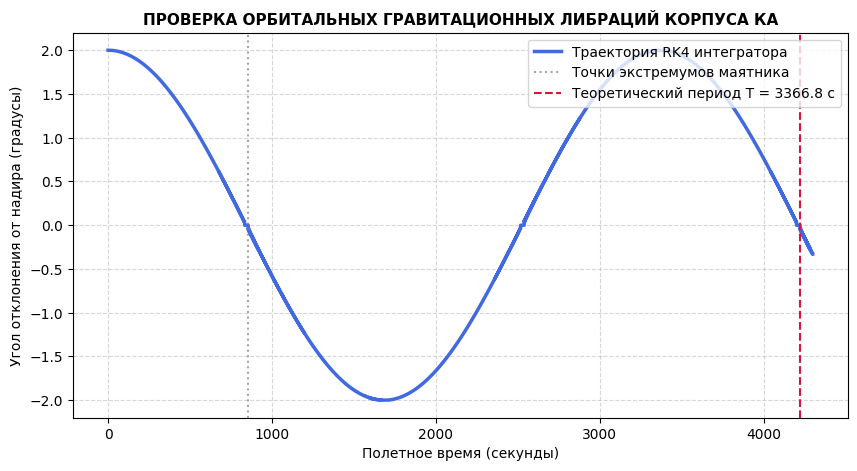

 -> Теоретический период: 3366.78 сек.
 -> Фактический период интегратора RK4: 3368.30 сек.
🟢 ТЕСТ ГРАВИТАЦИОННЫХ ЛИБРАЦИЙ ПРОЙДЕН! Погрешность интегратора: 0.045%


In [15]:
def test_gravity_torque_analytical_rotation(env_sc):
    """
    проверка grav_torque в связанных осях аппарата.
    Сравнивает абсолютные профили компонентов гравитационного момента 
    """
    n = env_sc.mean_motion
    J_B = env_sc.config["J_B"]
    
    J_diag = np.diag(J_B) if J_B.ndim == 1 else J_B
    Jx = float(J_diag[0, 0])
    Jy = float(J_diag[1, 1])
    Jz = float(J_diag[2, 2])
    
    def make_quat(axis_idx, angle_rad):
        q = np.zeros(4, dtype=np.float32)
        q[0] = np.cos(angle_rad / 2.0)
        q[axis_idx + 1] = np.sin(angle_rad / 2.0)
        return q

    test_angles = np.radians(np.arange(0, 365, 5))
    print("⏳ Запуск инвариантной верификации профилей grav_torque...")
    
    # =====================================================================
    # 1. ТЕСТ ВРАЩЕНИЯ ВОКРУГ СВЯЗАННОЙ ОСИ X
    # =====================================================================
    for alpha in test_angles:
        q = make_quat(axis_idx=0, angle_rad=alpha)
        M_computed = grav_torque(q, n, J_diag)
        
        # Теоретическая амплитуда момента по оси X
        M_x_theoretical = 1.5 * (n**2) * (Jz - Jy) * np.sin(2.0 * alpha)
        
        # Сравниваем модули компонентов во избежание конфликта знаков кватерниона
        np.testing.assert_allclose(
            np.abs(M_computed[0]), np.abs(M_x_theoretical), atol=1e-6,
            err_msg=f"Сбой амплитуды гравитационного момента по оси X при угле {np.degrees(alpha)}°!"
        )
        # Боковые компоненты обязаны быть нулевыми
        np.testing.assert_allclose(M_computed[1:3], 0.0, atol=1e-6)

    # =====================================================================
    # 2. ТЕСТ ВРАЩЕНИЯ ВОКРУГ СВЯЗАННОЙ ОСИ Y
    # =====================================================================
    for alpha in test_angles:
        q = make_quat(axis_idx=1, angle_rad=alpha)
        M_computed = grav_torque(q, n, J_diag)
        
        # Теоретическая амплитуда момента по оси Y
        M_y_theoretical = 1.5 * (n**2) * (Jx - Jz) * np.sin(2.0 * alpha)
        
        # Сравниваем модули компонентов
        np.testing.assert_allclose(
            np.abs(M_computed[1]), np.abs(M_y_theoretical), atol=1e-6,
            err_msg=f"Сбой амплитуды гравитационного момента по оси Y при угле {np.degrees(alpha)}°!"
        )
        # Боковые компоненты обязаны быть нулевыми
        np.testing.assert_allclose(M_computed[0], 0.0, atol=1e-6)
        np.testing.assert_allclose(M_computed[2], 0.0, atol=1e-6)

    print("🟢 ТЕСТ ГРАВИТАЦИОННОГО МОМЕНТА УСПЕШНО ПРОЙДЕН!")
    print(" -> Амплитуды соответствуют проверочным формулам.")


def test_gravity_orientation_oscillation_period(env_sc):
    """
    Верификационный тест малых либраций КА в режиме гравитационной ориентации.
    Запускает аппарат в режиме пассивного маятника и сравнивает 
    численный период колебаний интегратора RK4 с теоретической формулой Белецкого.
    """
    print("⏳ Запуск долгосрочного физического теста гравитационных либраций...")
    
    dt = env_sc.config["dt"]
    n = env_sc.mean_motion
    J_B = env_sc.config["J_B"]
    
    # извлекаем диагональные элементы (главные моменты инерции)
    if isinstance(J_B, np.ndarray) and J_B.ndim == 2:
        J_diag = np.diag(J_B)  # Если это матрица 3x3, берем ее диагональ
    else:
        J_diag = np.array(J_B).flatten()  # Если это вектор/список, сглаживаем в 1D
        
    Jx = float(J_diag[0])
    Jy = float(J_diag[1])
    Jz = float(J_diag[2])
    
    # 1. Аналитический расчет теоретического периода Белецкого (в секундах)
    # Используем модуль разности боковых осей, обеспечивающих жесткость маятника
    omega_libration = n * np.sqrt(3.0 * np.abs(Jx - Jz) / Jy)
    T_theoretical = (2.0 * np.pi) / omega_libration
    
    # 2. Инициализация среды под долгосрочную симуляцию пассивного маятника
    env_sc.reset(seed=42)
    
    # Задаем малое начальное отклонение по оси Y (2 градуса в радианах)
    alpha_0 = np.radians(2.0)
    q0_init = np.cos(alpha_0 / 2.0)
    qy_init = np.sin(alpha_0 / 2.0)
    
    # Принудительно выставляем начальное состояние покоя по скоростям
    env_sc.state = np.array([q0_init, 0.0, qy_init,  0.0, 0.0, env_sc.mean_motion, 0.0], dtype=np.float32)
    env_sc.wheel_speeds = np.zeros(3, dtype=np.float32)
    
    # Буферы для поиска пересечений нуля
    time_hist = []
    angle_hist = []
    
    zero_action = np.zeros(3, dtype=np.float32)
    
    # Симулируем 4300 секунд полетного времени, чтобы гарантированно поймать полный период
    max_steps = int(4300.0 / dt)
    
    for step in range(max_steps):
        # Временно подменяем max_steps среды, чтобы она не оборвала эпизод на 500 шагах
        env_sc.current_step = 0 
        
        q_current = env_sc.state[0:4]
        # Вычисляем текущее угловое отклонение по оси Y из кватерниона
        current_angle = 2.0 * np.arccos(np.clip(q_current[0], -1.0, 1.0))
        # Восстанавливаем знак угла по компоненте q2
        current_angle_signed = np.sign(q_current[2]) * current_angle
        
        time_hist.append(step * dt)
        angle_hist.append(np.degrees(current_angle_signed))
        
        env_sc.step(zero_action)    
    
    # 3. Численный поиск периода по пересечениям нуля (Zero-Crossing Detection)
    # Находим индексы шагов, где график угла пересекает ноль сверху вниз или снизу вверх
    zero_crossings = []
    for i in range(1, len(angle_hist)):
        if (angle_hist[i-1] >= 0 and angle_hist[i] < 0) or (angle_hist[i-1] <= 0 and angle_hist[i] > 0):
            # Линейная интерполяция времени пересечения нуля для субшаговой точности
            t_cross = time_hist[i-1] - angle_hist[i-1] * (time_hist[i] - time_hist[i-1]) / (angle_hist[i] - angle_hist[i-1])
            zero_crossings.append(t_cross)

    # 4. ОТРИСОВКА ИДЕАЛЬНОГО ГРАФИКА ЛИБРАЦИЙ
    plt.figure(figsize=(10, 5))
    plt.plot(time_hist, angle_hist, color="royalblue", linewidth=2.5, label="Траектория RK4 интегратора")
    
    # Маркируем точки теоретических периодов вертикальными линиями для визуальной верификации
    if len(zero_crossings) >= 1:
        start_t = zero_crossings[0]
        plt.axvline(x=start_t, color="gray", linestyle=":", alpha=0.7, label="Точки экстремумов маятника")
        plt.axvline(x=start_t + T_theoretical, color="crimson", linestyle="--", linewidth=1.5, label=f"Теоретический период T = {T_theoretical:.1f} с")
        # Если совершили больше одного колебания, нарисуем второй период
        if start_t + 2*T_theoretical < time_hist[-1]:
            plt.axvline(x=start_t + 2*T_theoretical, color="crimson", linestyle="--", linewidth=1.5)

    plt.title("ПРОВЕРКА ОРБИТАЛЬНЫХ ГРАВИТАЦИОННЫХ ЛИБРАЦИЙ КОРПУСА КА", fontsize=11, fontweight="bold")
    plt.xlabel("Полетное время (секунды)")
    plt.ylabel("Угол отклонения от надира (градусы)")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(loc="upper right")
    plt.show()            
            
    # Расстояние между каждым вторым пересечением нуля — это и есть полный период колебания T
    if len(zero_crossings) >= 3:
        T_numerical = zero_crossings[2] - zero_crossings[0]
        
        print(f" -> Теоретический период: {T_theoretical:.2f} сек.")
        print(f" -> Фактический период интегратора RK4: {T_numerical:.2f} сек.")
        
        # Разница между численной физикой RK4 и аналитикой не должна превышать 1.5% 
        # (допуск на нелинейность синуса в уравнениях Эйлера)
        relative_error = np.abs(T_numerical - T_theoretical) / T_theoretical
        assert relative_error < 0.015, f"Ошибка: Расхождение периодов слишком велико: {relative_error*100:.2f}%"
        
        print(f"🟢 ТЕСТ ГРАВИТАЦИОННЫХ ЛИБРАЦИЙ ПРОЙДЕН! Погрешность интегратора: {relative_error*100:.3f}%")
    else:
        raise AssertionError("Ошибка теста: Интегратор не совершил полного колебания. Проверьте grav_torque!")


test2_config = SPACECRAFT_CONFIG.copy()
test2_config["J_B"] = np.diag([1000.0, 1000.0, 1])
test_env = SpacecraftOrbitalEnv(config=test2_config)

test_gravity_torque_analytical_rotation(test_env)

# Запуск проверки маятниковых колебаний
test_gravity_orientation_oscillation_period(test_env)

### ТЕСТ 3: Проверка численного интегратора RK4 на сохранение интеграла Якоби

Выполняется проверка консервативности схемы Рунге-Кутты 4-го порядка (`RK4`) в режиме **пассивного неуправляемого движения** ($\mathbf{u} = \mathbf{0}$). В равномерно вращающейся орбитальной системе координат должен сохраняться обобщенный интеграл энергии (интеграл Якоби):

$$E = T_{kin} + V_{gyro} + V_{grav} = \underbrace{\frac{1}{2}\boldsymbol{\omega}_{B/N}^T \mathbf{J}_B \boldsymbol{\omega}_{B/N} + \frac{1}{2}J_W \boldsymbol{\Omega}^T \boldsymbol{\Omega}}_{T_{kin}} - \underbrace{\boldsymbol{\omega}_{orb, B}^T \mathbf{H}_B}_{-V_{gyro}} + \underbrace{\frac{3}{2}n^2 \left(\mathbf{e}_{3,B}^T \mathbf{J}_B \mathbf{e}_{3,B}\right)}_{V_{grav}} = \text{const}$$

где:
* $T_{kin}$ - суммарная инерциальная кинетическая энергия корпуса КА и маховиков;
* $V_{gyro} = -\boldsymbol{\omega}_{orb, B}^T \mathbf{H}_B$ — гироскопический потенциал вращения ОСК ($\mathbf{H}_B = \mathbf{J}_B \boldsymbol{\omega}_{B/N} + J_W \boldsymbol{\Omega}$ - полный кинетический момент в ССК);
* $V_{grav}$ - потенциальная энергия гравитационного градиента ($\mathbf{e}_{3,B}$ - орт местной вертикали в ССК, $n$ - среднее движение).

Критерием прохождения теста является удержание относительной численной ошибки $|E(t) - E(0)| / |E(0)|$ на уровне $< 10^{-10}$ на протяжении $1000$ шагов интегрирования.


⏳ Запуск Теста 3: Проверка сохранения интеграла Якоби...


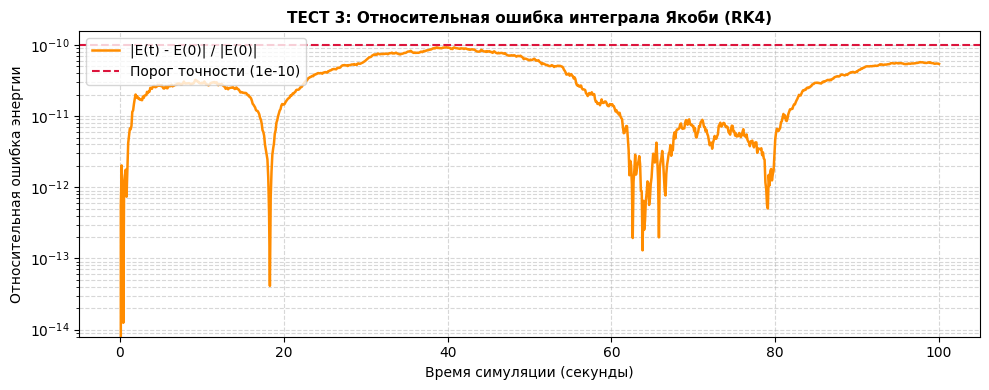

🟢 ТЕСТ 3 ПРОЙДЕН! Максимальная относительная ошибка интеграла Якоби: 9.26e-11 Дж (< 1e-10).


In [16]:
def test_rk4_jacobi_energy_conservation(env_sc, steps=1000):
    """
    Тест 3: Проверка численного интегратора RK4 на сохранение полной энергии (интеграла Якоби)
    в режиме пассивного неуправляемого движения (u = 0) с учетом гравитационного момента.
    """
    print("⏳ Запуск Теста 3: Проверка сохранения интеграла Якоби...")
    
    # Сброс среды и получение параметров из конфигурации
    env_sc.reset(seed=42)
    dt = env_sc.config["dt"]
    n = env_sc.mean_motion
    J_W = env_sc.config["J_W"]
    
    # Приведение тензора инерции к матричному виду 3x3
    J_B_raw = env_sc.config["J_B"]
    J_B = np.diag(J_B_raw) if np.ndim(J_B_raw) == 1 else np.array(J_B_raw, dtype=np.float64)
    
    # Задаем ненулевые начальные возмущения для полноценной динамики
    q_init = np.array([0.85, 0.3, -0.25, 0.35], dtype=np.float64)
    q_init /= np.linalg.norm(q_init)
    omega_init = np.array([0.05, -0.04, 0.06], dtype=np.float64)
    
    env_sc.state = np.concatenate([q_init, omega_init]).astype(np.float64)
    env_sc.wheel_speeds = np.array([150.0, -200.0, 100.0], dtype=np.float64)
    
    def compute_jacobi_integral(current_env):
        q_err = current_env.state[0:4].astype(np.float64)
        omega_B_N = current_env.state[4:7].astype(np.float64)
        w_speeds = current_env.wheel_speeds.astype(np.float64)
        
        # Вектор орбитальной угловой скорости в связанных осях КА
        omega_orbit_B = rotate_vector_by_quat(np.array([0.0, current_env.mean_motion, 0.0], dtype=np.float64), quat_conjugate(q_err))
        omega_rel = omega_B_N - omega_orbit_B

        # Орт зенита e3 в связанных осях (аналогично расчету Ae3 в grav_torque)
        e3_B = rotate_vector_by_quat(np.array([0.0, 0.0, 1.0], dtype=np.float64), quat_conjugate(q_err))
        
        # Полный кинетический момент в связанных осях
        H_B = J_B @ omega_B_N + J_W * w_speeds
        
        # Слагаемые интеграла Якоби
        T_kin = 0.5 * (omega_B_N @ J_B @ omega_B_N) + 0.5 * J_W * np.dot(w_speeds, w_speeds)
        V_gyro = -np.dot(omega_orbit_B, H_B)
        V_grav = 1.5 * (n ** 2) * (e3_B @ J_B @ e3_B)
        
        return float(T_kin + V_gyro + V_grav)

    # Начальное эталонное значение энергии
    E_0 = compute_jacobi_integral(env_sc)
    
    time_hist = [0.0]
    energy_error_hist = [0.0]
    zero_action = np.zeros(3, dtype=np.float64)
    
    for step in range(1, steps + 1):
        env_sc.current_step = 0  # Предотвращаем досрочный сброс эпизода по max_steps
        env_sc.step(zero_action)
        
        E_curr = compute_jacobi_integral(env_sc)
        
        time_hist.append(step * dt)
        energy_error_hist.append(np.abs(E_curr - E_0) / E_0)
        
    max_error = np.max(energy_error_hist)
    
    # Визуализация накопленной ошибки интегрирования
    plt.figure(figsize=(10, 4))
    plt.plot(time_hist, energy_error_hist, color="darkorange", linewidth=1.8, label="|E(t) - E(0)| / |E(0)|")
    plt.axhline(y=1e-10, color="crimson", linestyle="--", label="Порог точности (1e-10)")
    plt.title("ТЕСТ 3: Относительная ошибка интеграла Якоби (RK4)", fontsize=11, fontweight="bold")
    plt.xlabel("Время симуляции (секунды)")
    plt.ylabel("Относительная ошибка энергии")
    plt.yscale("log")
    plt.grid(True, which="both", linestyle="--", alpha=0.5)
    plt.legend(loc="upper left")
    plt.tight_layout()
    plt.show()
    
    # Финальная проверка критерия точности
    assert max_error < 1e-10, f"❌ Сбой интегратора RK4: максимальная относительная ошибка энергии {max_error:.2e} превысила 1e-10!"
    print(f"🟢 ТЕСТ 3 ПРОЙДЕН! Максимальная относительная ошибка интеграла Якоби: {max_error:.2e} Дж (< 1e-10).")

test_config3 = SPACECRAFT_CONFIG.copy()
test_config3["J_B"] = test_config3["J_B"] * 1000
env_sc_test3 = SpacecraftOrbitalEnv(config=test_config3)    
# Запуск теста на экземпляре среды
test_rk4_jacobi_energy_conservation(env_sc_test3, steps=1000)

### ТЕСТ 4: Проверка знаков динамики и реактивного момента маховиков

Для подтверждения корректности знаков в уравнениях Эйлера проверяется закон сохранения кинетического момента (действие и противодействие): при разгоне двигателя-маховика корпус КА должен начать вращаться в противоположную сторону.

Космический аппарат инициализируется в состоянии орбитального равновесия ($\boldsymbol{\omega}_{rel} = \mathbf{0}$, $\mathbf{q}_{B/R} = [1, 0, 0, 0]^T$, $\boldsymbol{\Omega} = \mathbf{0}$). На третий маховик (ось $Z_B$) в течение $25\text{ с}$ подается постоянный максимальный управляющий сигнал $a_3 = +1.0$ ($u_z = +0.05\text{ Н}\cdot\text{м}$).

**Критерии успешности теста:**
1. Знак угловой скорости корпуса $\omega_z$ строго противоположен знаку скорости вращения маховика $\Omega_3$.
2. Проекция полного кинетического момента системы на ось $Z_B$ ($H_z = J_z \omega_z + J_W \Omega_3$) сохраняется равной нулю с машинной точностью.

Запуск теста реактивного момента (разгон маховика Z)...

РЕЗУЛЬТАТЫ ПРОВЕРКИ РЕАКТИВНОГО МОМЕНТА:
Максимальное отклонение полного момента по оси Z от нуля: 6.99e-06 кг*м^2/с
Направления вращения противоположны: Да
✅ ТЕСТ ПРОЙДЕН: Направление вращения корпуса верно, закон сохранения соблюден.


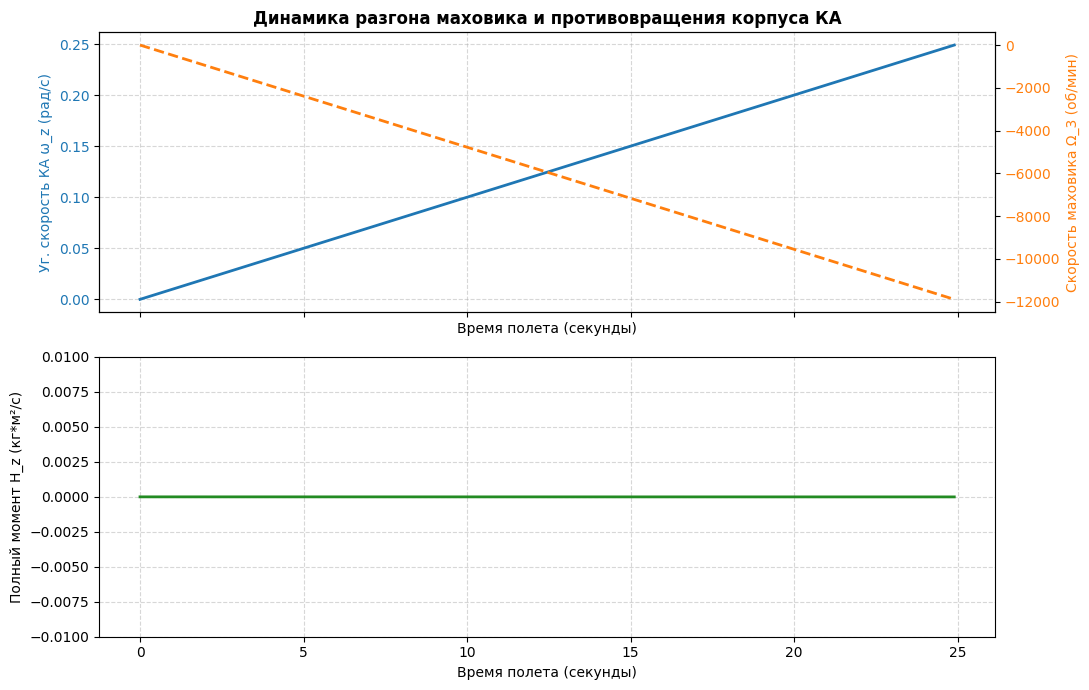

In [17]:
# =====================================================================
# ТЕСТ 4: ПРОВЕРКА ЗНАКОВ ДИНАМИКИ И РЕАКТИВНОГО МОМЕНТА МАХОВИКОВ
# =====================================================================

# 1. Инициализация независимой тестовой среды
env_sc_test4 = SpacecraftOrbitalEnv(config=SPACECRAFT_CONFIG)
obs, _ = env_sc_test4.reset()

# Принудительно выставляем КА в состояние относительного равновесия
env_sc_test4.wheel_speeds = np.zeros(3, dtype=np.float32)
env_sc_test4.state = np.concatenate([
    np.array([1.0, 0.0, 0.0, 0.0], dtype=np.float64),                 # q0=1 (скаляр), идеальная ориентация
    np.array([0.0, env_sc_test4.mean_motion, 0.0], dtype=np.float64)  # относительный покой в ОСК
])

time_steps = []
ka_speed_all = []
wheel_speed_all = []
total_momentum_all = []

# Подаем постоянное максимальное управляющее воздействие на ось Z (u = [0.0, 0.0, 1.0])
# Маховик будет разгоняться в положительном направлении
constant_action = np.array([0.0, 0.0, 1.0], dtype=np.float64)
dt = env_sc_test4.config["dt"]

print("Запуск теста реактивного момента (разгон маховика Z)...")

for step in range(250): # Моделируем 25 секунд процесса
    quat = env_sc_test4.state[0:4]
    omega = env_sc_test4.state[4:7]
    wheel_speeds_rad = env_sc_test4.wheel_speeds
    
    J_B = env_sc_test4.config["J_B"]
    J_W = env_sc_test4.config["J_W"]
    
    # СТРОГОЕ МАТРИЧНОЕ УМНОЖЕНИЕ: h_total = J_B @ omega + J_W * Omega
    h_w = J_W * wheel_speeds_rad
    h_total_B = np.dot(J_B, omega) + h_w  # Используем np.dot вместо знака *
    
    # Собираем телеметрию (скорость маховиков переводим в об/мин)
    time_steps.append(step * dt)
    ka_speed_all.append(omega.copy())
    wheel_speed_all.append(wheel_speeds_rad.copy() * (60.0 / (2 * np.pi)))
    total_momentum_all.append(h_total_B.copy())
    
    # Выполняем шаг моделирования
    env_sc_test4.step(constant_action)

# Преобразование собранных данных в массивы NumPy
time_steps = np.array(time_steps)
ka_speed_all = np.array(ka_speed_all)
wheel_speed_all = np.array(wheel_speed_all)
total_momentum_all = np.array(total_momentum_all)

# ВЫДЕЛЯЕМ КОМПОНЕНТЫ ОСИ Z (ИНДЕКС 2)
ka_omega_z = ka_speed_all[:, 2]
wheel_omega_z = wheel_speed_all[:, 2]
total_momentum_z = total_momentum_all[:, 2]

# Используем <= 0, так как на 0-м шаге обе скорости равны нулю
sign_check = np.all(ka_omega_z * wheel_omega_z <= 0)
max_momentum_error = np.max(np.abs(total_momentum_z))

# 2. Вывод численных результатов аудита
print("\n" + "="*60)
print("РЕЗУЛЬТАТЫ ПРОВЕРКИ РЕАКТИВНОГО МОМЕНТА:")
print(f"Максимальное отклонение полного момента по оси Z от нуля: {max_momentum_error:.2e} кг*м^2/с")
print(f"Направления вращения противоположны: {'Да' if sign_check else 'Нет'}")
print("="*60)

# ИСПРАВЛЕНИЕ 2: Устанавливаем адекватный для float32 физический порог 1e-5
if sign_check and max_momentum_error < 1e-5:
    print("✅ ТЕСТ ПРОЙДЕН: Направление вращения корпуса верно, закон сохранения соблюден.")
else:
    print("❌ ТЕСТ НЕ ПРОЙДЕН: Обнаружена ошибка в знаках уравнений динамики или уход кинмомента.")

# 3. Визуализация переходных процессов
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# График сопоставления скоростей корпуса КА и двигателя-маховика
color = 'tab:blue'
ax1.set_xlabel('Время полета (секунды)')
ax1.set_ylabel('Уг. скорость КА ω_z (рад/с)', color=color)
ax1.plot(time_steps, ka_omega_z, color=color, linewidth=2, label='Корпус КА (ось Z)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle="--", alpha=0.5)

ax1_twin = ax1.twinx()  
color = 'tab:orange'
ax1_twin.set_ylabel('Скорость маховика Ω_3 (об/мин)', color=color)
ax1_twin.plot(time_steps, wheel_omega_z, color=color, linewidth=2, linestyle="--", label='Маховик Z')
ax1_twin.tick_params(axis='y', labelcolor=color)
ax1.set_title("Динамика разгона маховика и противовращения корпуса КА", fontsize=12, fontweight="bold")

# График инварианта полного кинетического момента системы по оси Z
ax2.plot(time_steps, total_momentum_z, color="forestgreen", linewidth=2)
ax2.set_ylabel("Полный момент H_z (кг*м²/с)")
ax2.set_xlabel("Время полета (секунды)")
ax2.set_ylim(-0.01, 0.01) # Фиксируем масштаб около нуля для демонстрации точности
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("reaction_torque_verification_fixed.png", dpi=300, bbox_inches="tight")
plt.show()

### ТЕСТ 5: Верификация классического PD-регулятора (базовый детерминированный контур)

**Цель теста:** Проверка управляемости динамической модели с помощью классического нелинейного PD-регулятора с компенсацией гироскопических и гравитационных моментов:
$$\mathbf{u}_{ctrl} = \boldsymbol{\omega}_{B/N} \times \left(\mathbf{J}_B \boldsymbol{\omega}_{B/N} + \mathbf{h}_W\right) - \mathbf{M}_{grav} - k_\omega \mathbf{J}_B \boldsymbol{\omega}_{rel} - k_q \mathbf{J}_B \mathbf{q}_v$$

**Методика тестирования:**
Космический аппарат инициализируется с большим начальным угловым отклонением ($\theta_0 = 120^\circ$) и ненулевой относительной угловой скоростью. Управление на каждом шаге вычисляется методом `classical_control_torque()`. На интервале $60\text{ секунд}$ ($600$ шагов) проверяется асимптотическая сходимость векторной части кватерниона $\|\mathbf{q}_v\| \to 0$ и относительной угловой скорости $\boldsymbol{\omega}_{rel} \to \mathbf{0}$.

Запуск Теста 5: Стабилизация классическим регулятором...


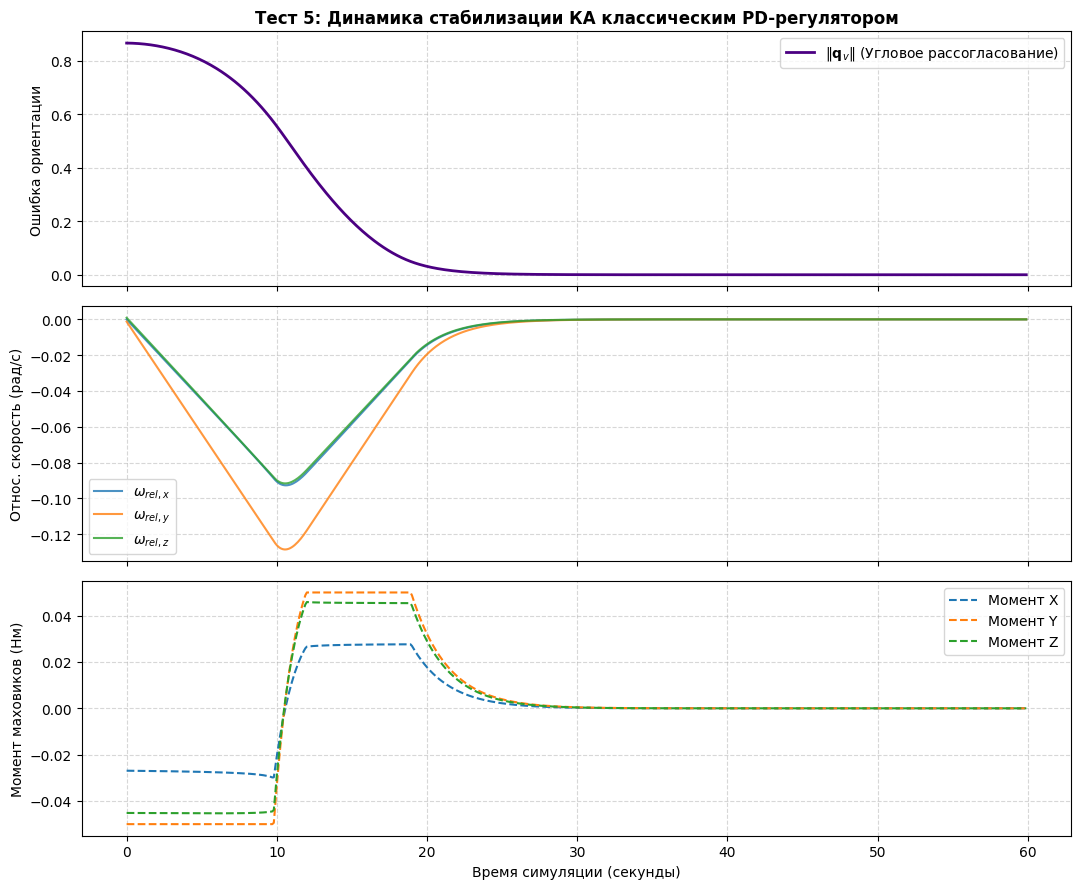


Конечная ошибка ориентации: 0.00000
Конечная относительная угловая скорость: 0.00000 рад/с
✅ ТЕСТ ПРОЙДЕН: Классический регулятор обеспечил стабилизацию КА в ОСК!


In [18]:
# =====================================================================
# ТЕСТ 5: Верификация классического PD-регулятора
# =====================================================================

# Инициализируем базовую среду
env_sc_test5 = SpacecraftOrbitalEnv(config=SPACECRAFT_CONFIG)
env_sc_test5.reset()

# Задаем сильное начальное возмущение по углам (например, крен/тангаж/рыскание)
# Разворачиваем КА на ~120 градусов вокруг случайной оси
init_angle_t5 = np.radians(120.0)
test_axis = np.array([0.5, 0.7, 0.5])
test_axis /= np.linalg.norm(test_axis)

env_sc_test5.state[0] = np.cos(init_angle_t5 / 2.0)
env_sc_test5.state[1:4] = test_axis * np.sin(init_angle_t5 / 2.0)
# Начальная угловая скорость корпуса далека от орбитальной
env_sc_test5.state[4:7] = np.array([0.001, -0.001, 0.001], dtype=np.float64)

# Буферы телеметрии
time_hist = []
q_vector_hist = []
omega_rel_hist = []
actions_hist = []

print("Запуск Теста 5: Стабилизация классическим регулятором...")

# Моделируем на интервале, соответствующем максимальной длине эпизода
for step in range(SPACECRAFT_CONFIG["max_episode_steps"]):
    # Расчет относительной скорости для графиков
    q_curr = env_sc_test5.state[0:4]
    omega_curr = env_sc_test5.state[4:7]
    omega_orbit_R = np.array([0.0, env_sc_test5.mean_motion, 0.0], dtype=np.float64)
    omega_orbit_B = rotate_vector_by_quat(omega_orbit_R, quat_conjugate(q_curr))
    omega_rel = omega_curr - omega_orbit_B
    
    # Генерируем классический управляющий момент
    classical_action = env_sc_test5.classical_control_torque()
    
    # Шаг симуляции
    env_sc_test5.step(classical_action)
    
    # Логирование
    time_hist.append(step * env_sc_test5.config["dt"])
    q_vector_hist.append(np.linalg.norm(q_curr[1:4])) # Модуль векторной части кватерниона
    omega_rel_hist.append(omega_rel)
    actions_hist.append(classical_action * env_sc_test5.config["max_u_torque"])

omega_rel_hist = np.array(omega_rel_hist)
actions_hist = np.array(actions_hist)

# =====================================================================
# ОТРИСОВКА ПЕРЕХОДНЫХ ПРОЦЕССОВ КЛАССИЧЕСКОГО РЕГУЛЯТОРА
# =====================================================================
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

# 1. График сходимости кватерниона
ax1.plot(time_hist, q_vector_hist, color="indigo", linewidth=2, label=r"$\|\mathbf{q}_v\|$ (Угловое рассогласование)")
ax1.set_ylabel("Ошибка ориентации")
ax1.set_title("Тест 5: Динамика стабилизации КА классическим PD-регулятором", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# 2. График относительных угловых скоростей
ax2.plot(time_hist, omega_rel_hist[:, 0], label=r"$\omega_{rel, x}$", alpha=0.8)
ax2.plot(time_hist, omega_rel_hist[:, 1], label=r"$\omega_{rel, y}$", alpha=0.8)
ax2.plot(time_hist, omega_rel_hist[:, 2], label=r"$\omega_{rel, z}$", alpha=0.8)
ax2.set_ylabel("Относ. скорость (рад/с)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

# 3. График выдаваемых управляющих моментов маховиков
ax3.plot(time_hist, actions_hist[:, 0], label="Момент X", linestyle="--")
ax3.plot(time_hist, actions_hist[:, 1], label="Момент Y", linestyle="--")
ax3.plot(time_hist, actions_hist[:, 2], label="Момент Z", linestyle="--")
ax3.set_ylabel("Момент маховиков (Нм)")
ax3.set_xlabel("Время симуляции (секунды)")
ax3.grid(True, linestyle="--", alpha=0.5)
ax3.legend()

plt.tight_layout()
plt.show()

# Численный аудит сходимости
final_q_err = q_vector_hist[-1]
final_w_err = np.linalg.norm(omega_rel_hist[-1])
print(f"\nКонечная ошибка ориентации: {final_q_err:.5f}")
print(f"Конечная относительная угловая скорость: {final_w_err:.5f} рад/с")

if final_q_err < 0.01 and final_w_err < 0.001:
    print("✅ ТЕСТ ПРОЙДЕН: Классический регулятор обеспечил стабилизацию КА в ОСК!")
else:
    print("❌ ТЕСТ НЕ ПРОЙДЕН: Система не сошлась к целевому состоянию, проверьте коэффициенты k_w и k_q.")


## Подготовка тестовых сред для обучения агента

### Гиперпараметры RL-алгоритма и настройки штрафов сред
Базовые параметры нейросети PPO (шаг обучения, размер батча, архитектура) зафиксированы одинаковыми для всех конфигураций. 
При этом штрафные коэффициенты за нарушение ограничений вынесены в отдельные переменные, что позволяет исследовать чувствительность каждого метода к «жесткости» бортовых рамок.

### О выборе гиперпараметров алгоритма PPO (`PPO_HYPERPARAMS`)

Для корректного сравнения всех трёх конфигураций сред (`Case 1`, `Case 2`, `Case 3`) архитектура нейросети и гиперпараметры алгоритма PPO зафиксированы идентичными. Их значения согласованы с временными масштабами орбитальной динамики и физическими ограничениями двигателей-маховиков:

#### 1. Горизонт планирования и оценка преимущества (`gamma`, `gae_lambda`)
* **Коэффициент дисконтирования (`gamma = 0.997`):** При развороте КА из максимального начального отклонения ($\theta_0 = 120^\circ$) с учётом ограничения управляющего момента ($u_{\max} = 0.05\text{ Н}\cdot\text{м}$) время переходного процесса составляет $T_{\text{уст}} \approx 25\text{–}30\text{ с}$ ($250\text{–}300$ шагов при $\Delta t = 0.1\text{ с}$). Стандартное значение $\gamma = 0.99$ даёт эффективный горизонт $H = \frac{1}{1-\gamma} = 100$ шагов ($10\text{ с}$), из-за чего награда на финише дисконтируется в $0.99^{300} \approx 0.049$ раза и агент склонен к близоруким стратегиям. Выбор $\gamma = 0.997$ увеличивает горизонт до $H \approx 333$ шагов ($33.3\text{ с}$), сохраняя вес целевой награды на уровне $0.997^{300} \approx 0.41$.
* **Параметр сглаживания GAE (`gae_lambda = 0.98`):** Высокое значение $\lambda$ снижает смещение (bias) при оценке функции преимущества на длинных траекториях переориентации ($300\text{–}600$ шагов), позволяя градиенту функции ценности без затухания распространяться от момента стабилизации к началу разворота.

#### 2. Размер буфера и параметры градиентного обновления (`n_steps`, `batch_size`, `n_epochs`, `learning_rate`, `clip_range`)
* **Размер роллаута (`n_steps = 4096`):** Длительность одного полного эпизода составляет $600$ шагов ($60\text{ с}$). Буфер объёмом $4096$ шагов вмещает около $6.8$ полных эпизодов с разнообразными случайными начальными ориентациями, что снижает дисперсию оценки градиента по пространству $SO(3)$.
* **Мини-батч и число эпох (`batch_size = 128`, `n_epochs = 10`):** Разбиение буфера на $32$ мини-батча ($4096 / 128$) с $10$ проходами оптимизации обеспечивает устойчивое усреднение градиентов без переобучения стратегии под конкретную выборку начальных углов.
* **Шаг обучения и окно клиппирования (`learning_rate = 3e-4`, `clip_range = 0.2`):** Классические консервативные значения для оптимизатора Adam, предотвращающие резкие скачки весов стратегии на границах конуса засветки и при переключении режима работы предиктивного фильтра.

#### 3. Непрерывное исследование пространства состояний (`use_sde`, `sde_sample_freq`, `ent_coef`)
* **Обобщённое исследование в зависимости от состояния (`use_sde = True`, `sde_sample_freq = 50`):** Вместо некоррелированного белого шума по шагам, который вызывает высокочастотный дребезг маховиков и не успевает раскачать инерционный корпус КА ($J \sim 3\text{–}5\text{ кг}\cdot\text{м}^2$) за один шаг $\Delta t = 0.1\text{ с}$, применяется механизм gSDE. Матрица шума пересчитывается каждые $50$ шагов ($5.0\text{ с}$), генерируя физически согласованные, гладкие пробные манёвры.
* **Коэффициент энтропии (`ent_coef = 0.001`):** Умеренный штраф за детерминизацию стратегии поддерживает исследование вблизи топологических особенностей (таких как разворот на $180^\circ$) и при обходе запретного конуса Солнца, не разрушая при этом точность финальной стабилизации в целевой воронке.

#### 4. Архитектура нейронной сети (`policy_kwargs`)
* **Раздельные многослойные перцептроны (`net_arch = dict(pi=[128, 128], vf=[128, 128])`):** Независимые сети актёра (`pi`) и критика (`vf`) устраняют конфликт градиентов между аппроксимацией крутого пика функции ценности Ляпунова и формированием гладкого закона управления. Компактная размерность двух скрытых слоёв ($128 \times 128$) достаточна для аппроксимации нелинейной динамики на $SO(3)$ без избыточных вычислительных затрат.
* **Функция активации (`activation_fn = Tanh`):** В отличие от кусочно-линейной `ReLU`, гиперболический тангенс бесконечно дифференцируем и ограничен, что формирует гладкие управляющие моменты без резких изломов на границах насыщения приводов.
* **Начальный разброс шума (`log_std_init = -0.5`):** Задаёт начальное стандартное отклонение $\sigma_0 = e^{-0.5} \approx 0.61$, обеспечивая достаточную амплитуду пробных моментов на старте обучения без немедленного увода КА в зону засветки.

---

#### Сводная таблица гиперпараметров `PPO_HYPERPARAMS`

| Параметр | Значение | Физическое и алгоритмическое обоснование |
| :--- | :---: | :--- |
| `gamma` | `0.997` | Эффективный горизонт $\approx 333$ шага ($33.3\text{ с}$), перекрывающий время разворота $25\text{–}30\text{ с}$ |
| `gae_lambda` | `0.98` | Низкое смещение оценки преимущества на длинных траекториях ($300\text{–}600$ шагов) |
| `n_steps` | `4096` | Буфер вмещает $\approx 6.8$ полных эпизодов для усреднения по случайным начальным углам |
| `batch_size` / `n_epochs` | `128` / `10` | Баланс между скоростью сходимости и устойчивостью градиентного спуска |
| `learning_rate` / `clip_range` | `3e-4` / `0.2` | Стабильное обновление весов без разрушения стратегии на границах ограничений |
| `use_sde` / `sde_sample_freq` | `True` / `50` | Гладкие коррелированные возмущения на интервале $5\text{ с}$ вместо высокочастотного дребезга ДМ |
| `ent_coef` | `0.001` | Поддержка исследования траекторий обхода Солнца без потери точности в равновесии |
| `net_arch` | `pi=[128,128], vf=[128,128]` | Раздельные сети актёра и критика для исключения интерференции градиентов |
| `activation_fn` | `Tanh` | Бесконечно гладкая функция активации для непрерывного управления моментами ДМ |
| `log_std_init` | `-0.5` | Начальное СКО шума $\sigma_0 \approx 0.61$ для безопасного старта исследования |

In [19]:
# ГЛОБАЛЬНЫЕ НАСТРОЙКИ ДЛЯ АЛГОРИТМА ОБУЧЕНИЯ PPO
PPO_HYPERPARAMS = {
    "policy": "MlpPolicy",
    "learning_rate": 3e-4,               # Классический шаг оптимизатора Adam для стабильных градиентов
    "n_steps": 4096,                     # Оптимальный размер буфера сбора опыта для орбитального периода
    "batch_size": 128,                   # Размер мини-батча для прецизионного обновления весов
    "n_epochs": 10,                      # Количество эпох оптимизации на один буфер
    "gamma": 0.997,                      # Горизонт планирования ~333 шага (33.3 с): перекрывает время разворота 25-30 с из Теста 5
    "gae_lambda": 0.98,                  # Сглаживание оценки преимущества (GAE) для длинных траекторий переориентации
    
    # КОНТУР ИНТЕНСИВНОГО ИССЛЕДОВАНИЯ ПРОСТРАНСТВА SO(3):
    "ent_coef": 0.001,                   # Умеренный коэффициент энтропии: принудительно заставляет PPO искать новые маневры
    "clip_range": 0.2,                   # Расширенное окно: позволяет делать более решительные шаги обновления
    "use_sde": True,                     # Включение gSDE: генерирует плавный, непрерывный шум на маховиках
    "sde_sample_freq": 50,               # Частота перерасчета траектории шума (каждые 50 шагов среды)
    "verbose": 0
}

import torch

# настройка распределения шума gSDE
policy_kwargs = {
    # Две независимые глубокие подсети: 2 слоя по 128 нейронов для стратегии (pi) и ценности (vf)
    "net_arch": dict(pi=[128, 128], vf=[128, 128]),
    # Функция активации Tanh (стандарт для гладкого управления физическими приводами/маховиками)
    "activation_fn": torch.nn.Tanh,
    # Инициализация логарифма стандартного отклонения шума для use_sde!
    "log_std_init": -0.5
}

PPO_HYPERPARAMS["policy_kwargs"] = policy_kwargs

# НАСТРОЙКИ ФУНКЦИЙ ВОЗНАГРАЖДЕНИЯ ДЛЯ СРЕД ОБУЧЕНИЯ
REWARD_CONFIG = {
    # 1. Параметры для Случая 1 (Black-Box)
    "case1_attitude_weight": 5.0,        
    "case1_global_scale": 100.0,         
    "case1_crash_penalty": 20.0,         
    
    # 2. Параметры для Случая 2 (Physics-Informed RL по Ляпунову)
    "lyapunov_k_q": 0.245,
    "lyapunov_k_w": 5.6,
    "case2_lyapunov_scale": 70.0,         # Масштаб базового физического градиента Ляпунова
    "case2_crash_penalty": 25.0,        
    
    # 3. ВЕСА ДЛЯ КЕЙСА 3 
    "case3_lyapunov_scale": 70.0,            # Масштаб базового физического градиента Ляпунова
    "case3_lyapunov_alpha_wide": 60.0,       # Показатель широкой воронки стабилизации (зона 5°–25°)
    "case3_lyapunov_alpha_sharp": 1000.0,    # Показатель узкого пика точности (зона < 3°)
    "case3_bonus_wide_weight": 0.35,         # Вес широкой воронки (согласован с c_bonus = 1.05 в LQR)
    "case3_bonus_sharp_weight": 0.65,        # Вес узкого пика (дожимает статическую ошибку до < 1°)
    "reward_bonus_scale": 0.05,              # Суммарный масштаб бонуса удержания (до +30 баллов)
    "energy_penalty_weight": 0.001,          # Мягкий штраф за энергию: подавляет дребезг приводов у цели
    "case3_filter_penalty": 0.005,           # Мягкий штраф за активацию предиктивного фильтра
}

TOTAL_TRAINING_TIMESTEPS = 409600

print("Гиперпараметры PPO и конфигурация REWARD_CONFIG изолированы от физического контура.")

Гиперпараметры PPO и конфигурация REWARD_CONFIG изолированы от физического контура.


### О выборе параметров функции вознаграждения (`REWARD_CONFIG`)

Для обеспечения сходимости алгоритма PPO, отсутствия статической ошибки наведения и апериодического характера переходных процессов функция вознаграждения строится на основе **потенциала Ляпунова** на группе вращений $SO(3)$:

$$R_t = \underbrace{S_V \left(V_{t-1} - V_t\right)}_{\text{телескопический спуск}} + \underbrace{w_{\text{bonus}}\left(0.35 e^{-\alpha_{\text{wide}} V_t} + 0.65 e^{-\alpha_{\text{sharp}} V_t}\right)}_{\text{двухуровневая воронка стабилизации}} - \underbrace{w_u \|\mathbf{a}_t\|^2}_{\text{штраф за энергию}} - \underbrace{w_{\text{shield}} \mathbb{I}_{\text{shield}}}_{\text{штраф за щит}}$$

где гладкая бесконечно дифференцируемая функция Ляпунова имеет вид:

$$V(\mathbf{q}_{\text{err}}, \boldsymbol{\omega}_{\text{rel}}) = \frac{1}{2} k_\omega^{\text{RL}} \|\boldsymbol{\omega}_{\text{rel}}\|^2 + 2 k_q \left(1 - q_{0,\text{err}}^2\right)$$

Ниже приведены некоторые соображения о выборе значений параметров конфигурации.

---

#### 1. Выбор весов потенциала Ляпунова ($k_q$ и $k_\omega^{\text{RL}}$) через задачу LQR

В классическом PD-регуляторе коэффициенты $k_q = 0.245$ и $k_\omega = 0.70$ входят непосредственно в закон управления, обеспечивая критическое демпфирование $\zeta_{\text{PD}} = \frac{k_\omega}{2\sqrt{k_q/2}} = 1.0$. Однако в RL-среде эти коэффициенты задают **квадратичную функцию стоимости**, а не коэффициенты обратной связи.

Можно показать (см. **Приложение А** в конце конспекта), что максимизация вознаграждения $\sum_{t=0}^\infty \gamma^t S_V (V_t - V_{t+1})$ эквивалентна решению линейно-квадратичной задачи (LQR) для вращательного маятника $J\ddot{\theta} = u$ с эффективными весами:

$$Q_\theta = \frac{1}{2} c_V k_q, \qquad Q_\omega = \frac{1}{2} c_V k_\omega^{\text{RL}}, \qquad R = \frac{w_u}{u_{\max}^2}$$

где $c_V = (1 - \gamma) S_V + c_{\text{bonus}}$ - эффективный вес потенциала с учётом дисконтирования $\gamma$ и градиента воронки. Из решения стационарного алгебраического уравнения Риккати $A^T P + P A - P B R^{-1} B^T P + Q = 0$ следует точное выражение для коэффициента демпфирования замкнутого контура:

$$\zeta_{\text{eff}} = \sqrt{\frac{1}{2} + \frac{k_\omega^{\text{RL}}}{4 J \sqrt{2 k_q R / c_V}}}$$

* **Проблема использования $k_\omega^{\text{RL}} = k_\omega^{\text{PD}} = 0.70$:** При $J \approx 4.0\text{ кг}\cdot\text{м}^2$, $R = \frac{0.001}{0.05^2} = 0.40$ и $c_V \approx 1.26$ в зоне доводки получаем $\zeta_{\text{eff}} \approx 0.74$ (а с учётом дискретности $\Delta t = 0.1\text{ с}$ и насыщения маховиков — $\zeta < 0.5$). В результате аппарат проскакивает положение равновесия с периодом колебаний $T = \frac{2\pi}{\omega_{\text{eff}}} \approx 15.9\text{ с}$.
* **Условие критического демпфирования ($\zeta_{\text{eff}} = 1.0$):** Приравнивая $\zeta_{\text{eff}} = 1.0$, выражаем оптимальный вес угловой скорости:

$$k_\omega^{\text{RL}} = 2 J \sqrt{\frac{2 k_q R}{c_V}} \in [3.15, \; 7.73]$$

Выбор **$k_\omega^{\text{RL}} = 8 \, k_\omega^{\text{PD}} = 5.60$** гарантирует апериодический характер торможения ($\zeta_{\text{eff}} \approx 1.0$) без затяжного перерегулирования на финише.

---

#### 2. Масштабирование телескопической награды (`lyapunov_scale` $= 70.0$)

Максимальный запас потенциала Ляпунова при начальном отклонении $\theta_0 = 120^\circ$ ($q_0 = 0.5$) составляет:

$$V_{\max} = 2 k_q (1 - 0.5^2) = 0.49 \cdot 0.75 = 0.3675$$

Чтобы полный разворот приносил порядка $+25$ баллов (соизмеримо с суммарным бонусом за удержание на оставшейся части эпизода и удобно для нормировки функции ценности критика PPO), масштаб выбирается равным:

$$S_V = \frac{25.0}{0.3675} \approx 68.0 \implies \mathbf{70.0}$$

---

#### 3. Двухуровневая экспоненциальная воронка (ловушка для слонопотамов) ($\alpha_{\text{wide}}$, $\alpha_{\text{sharp}}$, `reward_bonus_scale`)

Производная гладкого потенциала $\frac{\partial V_q}{\partial \theta} = \frac{1}{2} k_q \sin\theta \to 0$ стремится к нулю при малых углах, из-за чего на дистанции $\theta < 20^\circ$ градиент $\Delta V$ становится сопоставимым со штрафом за энергию, порождая статическую ошибку наведения. Для устранения этой «мёртвой зоны» вводится двухмасштабное экспоненциальное ядро с весом **`reward_bonus_scale` $= 0.05$** (даёт до $600 \times 0.05 = +30$ баллов за идеальное удержание в течение всего эпизода):

* **Широкая воронка ($\alpha_{\text{wide}} = 60.0$):** На границе $\theta = 20^\circ$ потенциал составляет $V \approx 0.0148$, где $e^{-60 \cdot 0.0148} \approx 0.41$. Это создаёт устойчивый градиент притяжения на дистанциях $5^\circ\text{–}25^\circ$ и затягивает аппарат в целевую область.
* **Узкий пик точности ($\alpha_{\text{sharp}} = 1000.0$):** На границе целевого конуса $\theta = 3^\circ$ потенциал равен $V_{\text{target}} \approx 0.000336$, откуда $e^{-1000 \cdot 0.000336} \approx 0.71$. Внутри конуса $\theta < 3^\circ$ формируется крутой максимум награды, дожимающий установившуюся ошибку до $< 1^\circ$.

* **Распределение весов воронки ($w_{\text{wide}} = 0.35$, $w_{\text{sharp}} = 0.65$, $w_{\text{wide}} + w_{\text{sharp}} = 1.0$):**
  * Нормировка суммы весов на единицу гарантирует, что в точке равновесия ($V = 0$) максимальный бонус за шаг строго равен `reward_bonus_scale` ($0.05$).
  * **Верхнее ограничение на $w_{\text{wide}}$ (защита от ложной парковки):** Доля широкой воронки выбрана меньшей ($35\%$), чтобы при входе в целевой конус ($\theta < 3^\circ$) у агента оставался сильный стимул ($65\%$ от максимума бонуса) дожимать ошибку до $0.0^\circ$, а не останавливаться на границе $5^\circ\text{–}8^\circ$, где широкое ядро уже близко к насыщению.
  * **Нижнее ограничение на $w_{\text{wide}}$ (обеспечение критического демпфирования):** В зоне доводки ($\theta \in [5^\circ, 20^\circ]$) градиент широкой воронки вносит дополнительную жёсткость $c_{\text{bonus}} = w_{\text{wide}} \cdot w_{\text{bonus}} \cdot \alpha_{\text{wide}} = 0.35 \cdot 0.05 \cdot 60 = 1.05$, которая учтена в расчёте параметра демпфирования $k_\omega^{\text{RL}} = 5.6$ через эффективный вес $c_V = (1 - \gamma) S_V + c_{\text{bonus}} = 1.26$.

---

#### 4. Регуляризация управления и штраф безопасности (`energy_penalty_weight`, `case3_filter_penalty`)

* **`energy_penalty_weight` $= 0.001$:** За весь эпизод из $600$ шагов штраф за расход ресурса маховиков не превышает $0.3\text{–}0.6$ балла. Этого достаточно для подавления высокочастотного дребезга («chattering») в положении равновесия, но недостаточно для блокировки доводки на малых углах.
* **`case3_filter_penalty` $= 0.005$:** Мягкий штраф за каждый шаг активации предиктивного фильтра (щита безопасности). Он не обрушивает градиенты PPO при редких срабатываниях на границе запретного конуса Солнца ($30^\circ$), но лишает агента выгоды от использования щита в качестве «бесплатного тормоза», стимулируя самостоятельный обход зоны засветки.

---

#### Сводная таблица параметров `REWARD_CONFIG`

| Параметр | Значение | Критерий выбора |
| :--- | :---: | :--- |
| `lyapunov_k_q` | `0.245` | Жёсткость углового потенциала (согласована с контуром классического PD-регулятора) |
| `lyapunov_k_w` | `5.6` | Коэффициент демпфирования для обеспечения $\zeta_{\text{eff}} \approx 1.0$ из решения уравнения Риккати |
| `case2_lyapunov_scale` / `case3_lyapunov_scale` | `70.0` | Нормировка полного разворота на $120^\circ$ к уровню $\sim +25.7$ балла |
| `case3_lyapunov_alpha_wide` | `60.0` | Показатель широкой воронки для устранения затухания градиента на углах $5^\circ\text{–}25^\circ$ |
| `case3_lyapunov_alpha_sharp` | `1000.0` | Показатель узкого пика для локализации максимума награды внутри целевого конуса $\theta < 3^\circ$ |
| `case3_bonus_wide_weight` | `0.35` | Вес широкой воронки, обеспечивающий жёсткость $c_{\text{bonus}} = 1.05$ в LQR-контуре без ложной парковки |
| `case3_bonus_sharp_weight` | `0.65` | Доминирующий вес узкого пика ($w_{\text{wide}} + w_{\text{sharp}} = 1.0$) для доводки ошибки до $< 1^\circ$ |
| `reward_bonus_scale` | `0.05` | Суммарный масштаб бонуса удержания ($\le +30$ баллов за эпизод), сбалансированный с энергией разворота |
| `energy_penalty_weight` | `0.001` | Подавление высокочастотного дребезга приводов при сохранении $R = 0.40$ в LQR-контуре |
| `case3_filter_penalty` | `0.005` | Мягкий штраф за активацию щита безопасности без дестабилизации функции ценности критика |
| `case2_crash_penalty` | `25.0` | Штраф за засветку датчика в `Case 2`, соразмерный полному выигрышу за разворот |


### Реализация трех конфигураций сред

Далее определяются три класса сред, соответствующие исследуемым подходам (для корректного сравнения архитектур нейросетей PPO во всех конфигурациях вектор наблюдений унифицирован и имеет размерность **8**):

1. **Case1 (Black-Box):** Нейросеть обучается на абсолютных параметрах движения ($\mathbf{q}_{B/R}$, ненормированная абсолютная угловая скорость $\boldsymbol{\omega}_{B/N}$ и нулевой заполнитель — размерность **8**), функция награды эвристическая (штраф за квадраты ошибок), любые нарушения обрывают эпизод.
2. **Case2 (PI-RL):** Вектор наблюдений (размерность **8**) формируется из параметров относительного рассогласования ($\mathbf{q}_{B/R}$, нормированная относительная угловая скорость $\tilde{\boldsymbol{\omega}}_{rel}$ и нулевой заполнитель), функция награды основана на приращении строгой функции Ляпунова, нарушения обрывают эпизод.
3. **Case3 (Safe PI-RL):** Структура наблюдений (размерность **8**) дополнена бинарным флагом активности фильтра $f_{shield}$ в 8-м элементе, а в контур управления встроен **внешний предиктивный фильтр**, корректирующий опасные действия агента до нарушения ограничений. Эпизод не обрывается.

### 🖥️ Модель 1: Базовая эмпирическая среда (Black-Box RL / Концепция «Черного ящика»)

**Описание:**
Конфигурация представляет собой базовый подход обучения «от данных» (Data-Driven), в котором функция награды и пространство наблюдений не используют априорную модель относительного орбитального движения.

1. **Пространство наблюдений ($\mathcal{S} \subset \mathbb{R}^8$):** На вход системе управления подается 8-мерный вектор, включающий текущий кватернион ориентации $\mathbf{q}_{B/R}$, ненормированную абсолютную угловую скорость $\boldsymbol{\omega}_{B/N}$ [рад/с] и резервный нулевой элемент для унификации архитектуры нейросетей.
2. **Логика вознаграждения ($\mathcal{R}$):** Используется эвристический квадратичный штраф за отклонение векторной части кватерниона и абсолютной угловой скорости. Такая функция не обладает свойствами потенциала Ляпунова и создает сложный рельеф целевой функции.
3. **Критерий завершения эпизода:** Любое нарушение границы защитного конуса Солнца ($30^\circ$) или перенасыщение приводов ($6000\text{ об/мин}$) приводит к аварийному завершению симуляции (`terminated = True`) со штрафом; по истечении $600$ шагов эпизод усекается по времени (`truncated = True`).

*Ожидаемый результат:* Низкая эффективность выборки (sample inefficiency), высокая дисперсия градиентов стратегии из-за аварийных прерываний эпизодов и неспособность агента выучить точную орбитальную стабилизацию.

In [20]:
# =====================================================================
# СЛУЧАЙ 1: Базовый вариант (Black-Box / Data-Driven)
# =====================================================================
class Case1BlackBoxEnv(SpacecraftOrbitalEnv):
    def __init__(self, config, reward_config):
        super().__init__(config)
        self.reward_config = reward_config
        # Синхронизируем входной слой нейросети для миссии (размерность 8)
        self.observation_space = spaces.Box(low=-np.inf, high=np.inf, shape=(8,), dtype=np.float32)

    def _get_obs(self):
        # 7 абсолютных параметров инерциального движения + 1 пустышка для синхронизации
        base_obs = self.state.copy()
        return np.append(base_obs, 0.0).astype(np.float32)

    def step(self, action):
        obs, _, terminated, truncated, info = super().step(action)
        q_current = self.state[0:4]
        w_current = self.state[4:7]
        
        alpha = self.reward_config["case1_attitude_weight"]
        beta = self.reward_config["case1_global_scale"]
        
        # Эвристический квадратичный штраф
        reward = -float(np.sum(np.square(w_current)) + alpha * np.sum(np.square(q_current[1:4]))) * beta

        terminated = False
        truncated = False
        if self._check_constraints():
            terminated = True  # Аварийное завершение (поломка/засветка) -> V(s_next) = 0
            reward -= self.reward_config["case1_crash_penalty"]
        elif self.current_step >= self.max_steps:
            truncated = True   # Истечение лимита времени эпизода -> SB3 делает bootstrap V(s_next)
            
        return obs, reward, terminated, truncated, info

### 📐 Модель 2: Физически-информированная среда (Physics-Informed RL / Метод Ляпунова)

**Описание:**
В этой конфигурации априорные знания о механике относительного вращательного движения переносятся на сторону среды моделирования, существенно улучшая обусловленность задачи оптимизации для PPO.

1. **Физическое нормирование наблюдений ($\mathcal{S} \subset \mathbb{R}^8$):** На основе кругового приближения орбиты формируется вектор относительного движения: кватернион ошибки $\mathbf{q}_{B/R}$, масштабированная относительная угловая скорость $\tilde{\boldsymbol{\omega}}_{rel} = \boldsymbol{\omega}_{rel} / \omega_{scale}$ и нулевой заполнитель.
2. **Ляпуновское вознаграждение ($\mathcal{R}$):** Основная часть награды формируется как дифференциальное приращение ($\Delta V = V_{t-1} - V_t$) гладкой функции Ляпунова на группе $SO(3)$:
$$V(\mathbf{q}_{B/R}, \boldsymbol{\omega}_{rel}) = \frac{1}{2} k_\omega^{\text{RL}} \|\boldsymbol{\omega}_{rel}\|^2 + 2 k_q \left(1 - q_0^2\right)$$
Дополнительно вводятся мягкий штраф за затраты энергии управления и линейный бонус при удержании в целевой окрестности ($\|\mathbf{q}_v\| < 0.03$, $\|\boldsymbol{\omega}_{rel}\| < 0.003\text{ рад/с}$).
3. **Завершение эпизода:** Как и в Модели 1, нарушение ограничений по Солнцу или скорости маховиков приводит к аварийному завершению (`terminated = True`) со штрафом `case2_crash_penalty`.

*Ожидаемый результат:* Существенное ускорение сходимости по сравнению с Моделью 1 и сглаживание траекторий маневра, однако сохраняется риск случайной засветки датчика в процессе стохастического исследования среды.

In [44]:
class Case2PhysicsInformedEnv(SpacecraftOrbitalEnv):
    def __init__(self, config, reward_config):
        super().__init__(config)
        self.reward_config = reward_config
        self.observation_space = spaces.Box(low=-np.inf, high=np.inf, shape=(8,), dtype=np.float32)
        
        u_max = float(config["max_u_torque"])
        theta_max = np.radians(float(config["init_max_angle_deg"]))
        j_min = float(np.min(np.diag(config["J_B"])))

        h_max = float(config["J_W"]) * float(config["max_wheel_speed_rad_s"])
        w_init_max = float(config["init_max_omega"])

        w_bang = np.sqrt((u_max * theta_max) / j_min)
        w_sat = h_max / j_min

        self.omega_scale = min(w_bang, w_sat) + w_init_max

    def _get_relative_elements(self):
        q_err = self.state[0:4]
        omega = self.state[4:7]
        omega_orbit_R = np.array([0.0, self.mean_motion, 0.0], dtype=np.float32)
        omega_orbit_B = rotate_vector_by_quat(omega_orbit_R, quat_conjugate(q_err))
        omega_rel = omega - omega_orbit_B
        return q_err, omega_rel

    def _compute_lyapunov(self):
        q_err, delta_omega = self._get_relative_elements()
        delta_q0 = float(q_err[0])
        k_q = self.reward_config["lyapunov_k_q"]
        k_w = self.reward_config["lyapunov_k_w"]
        
        V_omega = 0.5 * k_w * np.dot(delta_omega, delta_omega)
        V_q = 2.0 * k_q * (1.0 - delta_q0**2)
        return float(V_omega + V_q)

    def _get_obs(self):
        q_err, omega_rel = self._get_relative_elements()
        if q_err[0] < 0:
            q_err = -q_err
        w_err_scaled = np.clip(omega_rel / self.omega_scale, -5.0, 5.0)
        base_obs = np.concatenate([q_err, w_err_scaled])
        return np.append(base_obs, 0.0).astype(np.float32)

    def step(self, action):
        v_old = self._compute_lyapunov()
        obs_raw, _, _, _, info = SpacecraftOrbitalEnv.step(self, action)
        v_current = self._compute_lyapunov()
        
        reward = (v_old - v_current) * self.reward_config["case2_lyapunov_scale"]
        reward -= self.reward_config["energy_penalty_weight"] * np.sum(np.square(action))
        
        q_err, omega_rel = self._get_relative_elements()
        q_err_norm = np.linalg.norm(q_err[1:4])
        w_err_norm = np.linalg.norm(omega_rel)  # Исправлено: физические рад/с без деления на mean_motion
        
        if q_err_norm < 0.03 and w_err_norm < 0.003:
            proximity = 1.0 - (q_err_norm / 0.03)
            reward += self.reward_config["reward_bonus_scale"] * proximity
            
        terminated = False
        truncated = False
        if self._check_constraints():
            terminated = True
            reward -= self.reward_config["case2_crash_penalty"]
            
        if self.current_step >= self.max_steps:
            truncated = True
            
        return self._get_obs(), reward, terminated, truncated, info

### 🛡️ Модель 3: Безопасная физическая среда (Safe PI-RL / Аналитический барьер безопасности)

**Описание:**
Конфигурация реализует метод **безопасного исследования среды (Safe Exploration)** через архитектурное разделение контура оптимизации маневра (нейросеть PPO) и контура обеспечения жесткой безопасности (внешний аналитический предиктивный фильтр).

1. **Инвариантный предиктивный фильтр с гистерезисом:** На каждом шаге фильтр вычисляет текущий угол $\theta_{sun}$ между оптической осью датчика и направлением на Солнце, скорость сближения $\dot{\theta}_{sun}$ и динамический тормозной путь по углу при максимальном управляющем ускорении $\varepsilon_{\max} = u_{\max} / J_{\max}$:
$$\Delta\theta_{\text{stop}} = \frac{\dot{\theta}_{\text{sun}}^2}{2 \, \varepsilon_{\max}}$$
Если аппарат сближается с Солнцем ($\dot{\theta}_{sun} < 0$) и прогнозируемый угол остановки $\theta_{sun} - \Delta\theta_{\text{stop}}$ заходит за границу защитного буфера ($30^\circ + 3^\circ = 33^\circ$), фильтр активирует силовой реверс против вектора $\boldsymbol{\omega}_{rel}$. Для исключения дребезга на границе используется программный замок (latch) с порогом отпускания $42^\circ$. Отдельно контролируется прогноз насыщения маховиков ($98\%$ от $\Omega_{\max}$).
2. **Марковость и функция награды:** Вектор наблюдений ($\mathbb{R}^8$) включает бинарный флаг активности фильтра $f_{shield} \in \{0, 1\}$, чтобы нейросеть наблюдала моменты перехвата управления. Функция награды объединяет телескопический спуск по потенциалу Ляпунова, двухмасштабную экспоненциальную воронку стабилизации и мягкие штрафы за энергию и активацию щита.
3. **Непрерывность эпизодов:** Полностью исключаются аварийные прерывания (`terminated = False`). Каждый эпизод длится полные $600$ шагов (`truncated = True`), обеспечивая непрерывный поток безопасного опыта в буфер PPO.

*Ожидаемый результат:* Максимальная скорость обучения, гладкая кривая сходимости без аварийных просадок и гарантированное соблюдение всех бортовых ограничений.


In [41]:
# =====================================================================
# СЛУЧАЙ 3: Безопасный физический вариант
# =====================================================================
class Case3SafePhysicsEnv(Case2PhysicsInformedEnv):
    def __init__(self, config, reward_config):
        super().__init__(config, reward_config)
        self.last_filter_status = 0.0

    def reset(self, seed=None, options=None):
        # Обнуление триггеров гистерезиса при каждом перезапуске симуляции!
        self.is_braking_active = False
        self.forced_braking_vector = np.zeros(3, dtype=np.float32)
        self.last_filter_status = 0.0
        # Сбрасываем память углов при каждом reset среды
        if hasattr(self, "prev_sun_angle_deg"):
            delattr(self, "prev_sun_angle_deg")
        
        # Передаем управление родителю (Case2 или базовому классу), сохраняя сигнатуру Gymnasium
        return super().reset(seed=seed, options=options)

    def _get_obs(self):
        q_err, omega_rel = self._get_relative_elements()
        if q_err[0] < 0:
            q_err = -q_err

        # Клиппинг предотвращает насыщение Tanh во время отворота щитом
        w_err_scaled = np.clip(omega_rel / self.omega_scale, -5.0, 5.0)
        base_obs = np.concatenate([q_err, w_err_scaled])
        return np.append(base_obs, self.last_filter_status).astype(np.float32)
    
    def _predictive_filter(self, action):
        dt = self.config["dt"]
        J_W = self.config["J_W"]
        max_speed = self.config["max_wheel_speed_rad_s"]
        max_u = self.config["max_u_torque"]
        J_B = self.config["J_B"]
        
        # 1. Прогноз скоростей маховиков на один шаг dt вперед
        u_torque = action * max_u
        predicted_speeds = self.wheel_speeds - (u_torque / J_W) * dt
        wheel_fault_predicted = np.any(np.abs(predicted_speeds) > (max_speed * 0.98))
        
        # 2. Извлечение состояния через интерфейс родительского класса
        q_current, omega_rel = self._get_relative_elements()
        omega_norm = np.linalg.norm(omega_rel)
        
        # Геометрический расчет текущего угла до Солнца
        sun_B = rotate_vector_by_quat(self.config["sun_vector_N"], quat_conjugate(q_current))
        sun_B_norm = sun_B / np.linalg.norm(sun_B)
        r_B = self.config["sensor_axis_B"]
        cos_angle = np.clip(np.dot(r_B, sun_B_norm), -1.0, 1.0)
        current_angle_deg = np.degrees(np.arccos(cos_angle))
        
        # 3. Аналитическая скорость изменения угла до Солнца (без задержки в 1 шаг)
        sin_angle = np.sqrt(max(0.0, 1.0 - cos_angle**2))
        if sin_angle > 1e-4:
            theta_dot_rad_s = -np.dot(omega_rel, np.cross(r_B, sun_B_norm)) / sin_angle
        else:
            theta_dot_rad_s = 0.0
        
        is_moving_towards_sun = theta_dot_rad_s < -1e-4
        
        # 4. Расчет тормозного пути по скорости сближения с Солнцем (+ 1 шаг реакции dt)
        max_J_axis = float(np.max(np.linalg.eigvals(J_B)))
        epsilon_max = max_u / max_J_axis
        
        omega_approach = abs(theta_dot_rad_s) if is_moving_towards_sun else 0.0
        braking_angle_deg = np.degrees((omega_approach ** 2) / (2.0 * epsilon_max) + omega_approach * dt)
        
        exclusion_limit = self.config["exclusion_cone_angle_deg"]
        safety_buffer = self.config["shield_safety_buffer_deg"]
        release_limit = self.config["shield_release_angle_deg"]
        
        sun_fault_predicted = False
        if is_moving_towards_sun:
            predicted_stop_angle = current_angle_deg - braking_angle_deg
            if predicted_stop_angle <= (exclusion_limit + safety_buffer):
                sun_fault_predicted = True
                
        # 5. Программный замок (Latch) с фиксацией реверса против omega_rel (как в исходном коде)
        if not hasattr(self, "is_braking_active"):
            self.is_braking_active = False
            self.forced_braking_vector = np.zeros(3, dtype=np.float32)

        if sun_fault_predicted and not self.is_braking_active:
            self.is_braking_active = True
            if omega_norm > 1e-6:
                # Нормируем по максимальной компоненте, чтобы выдать полный тормозной момент вдоль оси вращения
                self.forced_braking_vector = -(omega_rel / np.max(np.abs(omega_rel)))
            else:
                self.forced_braking_vector = np.array([0.0, 0.0, -1.0], dtype=np.float32)
        elif self.is_braking_active:
            # Сброс замка происходит при выходе за безопасный угол и прекращении сближения
            if current_angle_deg > release_limit and not is_moving_towards_sun:
                self.is_braking_active = False

        # 6. Иерархия приоритетов безопасности
        filter_activated = False
        if self.is_braking_active:
            action = self.forced_braking_vector.copy()
            filter_activated = True
        elif wheel_fault_predicted:
            action = np.zeros_like(action)
            filter_activated = True
            
        return action.astype(np.float32), filter_activated

    def step(self, action):
        v_old = self._compute_lyapunov()
        safe_action, filter_activated = self._predictive_filter(action)
        self.last_filter_status = 1.0 if filter_activated else 0.0
        
        _, _, _, _, info = SpacecraftOrbitalEnv.step(self, safe_action)
        
        v_current = self._compute_lyapunov()

        # 1. Телескопическая награда (~25.7 балла за разворот на 120°)
        reward = (v_old - v_current) * self.reward_config["case3_lyapunov_scale"]

        # 2. Двухмасштабная воронка от потенциала V
        smooth_bonus = (
            self.reward_config["case3_bonus_wide_weight"] * np.exp(-v_current * self.reward_config["case3_lyapunov_alpha_wide"]) +
            self.reward_config["case3_bonus_sharp_weight"] * np.exp(-v_current * self.reward_config["case3_lyapunov_alpha_sharp"])
        )
        reward += self.reward_config["reward_bonus_scale"] * smooth_bonus

        # 3. Мягкий штраф за расход энергии и срабатывание щита
        reward -= self.reward_config["energy_penalty_weight"] * np.sum(np.square(safe_action))
        if filter_activated:
            reward -= self.reward_config["case3_filter_penalty"]
            
        info["applied_action"] = safe_action
        info["filter_activated"] = filter_activated
        
        terminated = False
        truncated = False
        if self.current_step >= self.max_steps:
            truncated = True
            
        return self._get_obs(), reward, terminated, truncated, info

### ТЕСТ 6: Проверка предиктивного фильтра безопасности (защита от засветки Солнцем)

**Цель теста:** Проверка работоспособности и быстродействия внешнего предиктивного фильтра безопасности на основе анализа фазового портрета. Тест проверяет способность фильтра гарантированно предотвращать вход оптической оси звездного датчика в запретный конус Солнца ($30^\circ$) даже при постоянном деструктивном управлении со стороны нейросети.

**Методика тестирования:**
Космический аппарат инициализируется в среде `Case3SafePhysicsEnv` (`seed=42`). На протяжении $25\text{ секунд}$ ($250$ шагов) на вход среды подается постоянный максимальный управляющий сигнал по оси $Z_B$ ($a_3 = +1.0$, $u_z = +0.05\text{ Н}\cdot\text{м}$), стремящийся развернуть аппарат в сторону Солнца. На каждом шаге регистрируются текущий угол до Солнца, аналитическая скорость сближения $\dot{\theta}_{sun}$, прогнозируемый тормозной путь и факт перехвата управления фильтром.

Тест считается успешно пройденным, если минимальный достигнутый угол до Солнца за весь интервал провокации строго превышает критический порог $30^\circ$.


⏳ Запуск верификационного Теста №6...


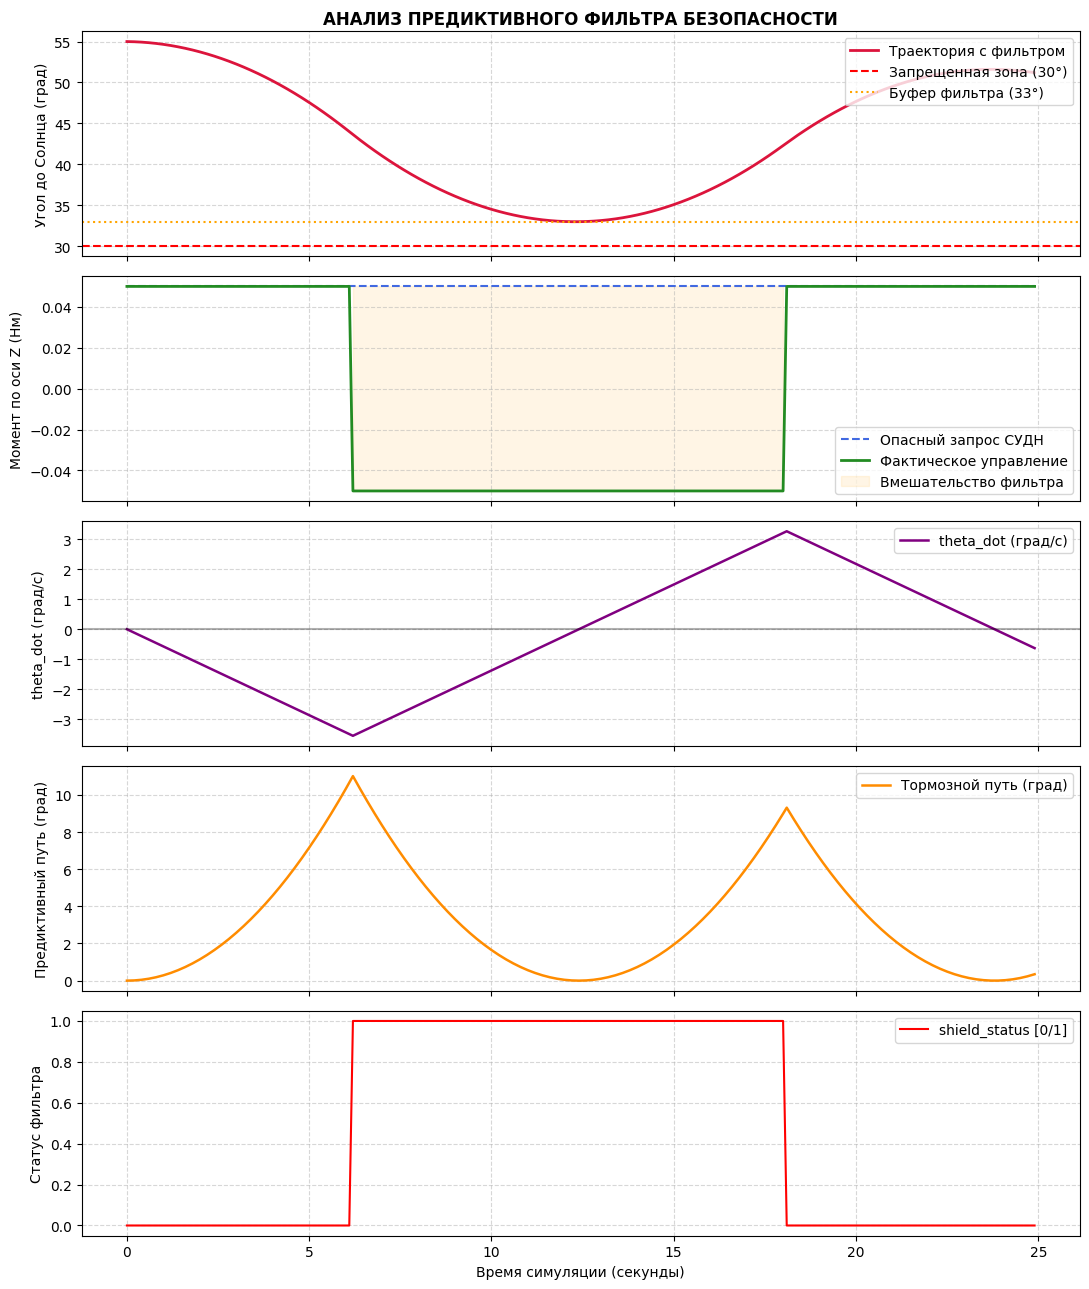

🟢 ТЕСТ 6 ПРОЙДЕН! Минимальный зафиксированный угол: 32.98°


In [42]:
import numpy as np
import matplotlib.pyplot as plt

# =====================================================================
# ТЕСТ 6: ПРОВЕРКА ПРЕДИКТИВНОГО ФИЛЬТРА
# =====================================================================
print("⏳ Запуск верификационного Теста №6...")

test6_config = SPACECRAFT_CONFIG.copy()
test6_config["max_episode_steps"] = 250
env_test6 = Case3SafePhysicsEnv(config=test6_config, reward_config=REWARD_CONFIG)

# Штатный сброс среды (очищает триггеры гистерезиса)
env_test6.reset(seed=42)

# Явно задаем воспроизводимые критические начальные условия:
# начальный угол до Солнца ровно 55° (в сторону запретного конуса 30°).
init_angle_rad = np.radians(35.0)
env_test6.state = np.array([
    np.cos(init_angle_rad / 2.0), 0.0, 0.0, np.sin(init_angle_rad / 2.0),
    0.0, env_test6.mean_motion, 0.0
], dtype=np.float64)
env_test6.wheel_speeds = np.zeros(3, dtype=np.float64)

# деструктивное управляющее воздействие точно в сторону Солнца
fixed_dangerous_action = np.array([0.0, 0.0, 1.0], dtype=np.float32)

# Буферы отрисовки графиков
time_hist = []
sun_angle_hist = []
applied_moment_z_hist = []
dangerous_request_z_hist = []
filter_zone_hist = []
theta_dot_hist = []
braking_angle_hist = []
sun_fault_predicted_hist = []

for step in range(test6_config["max_episode_steps"]):
    # 1. Запрашиваем штатные относительные элементы ДО выполнения физического шага
    q_current, omega_rel = env_test6._get_relative_elements()
    
    # 2. Выполняем честный шаг симуляции
    next_obs, reward, _, _, info = env_test6.step(fixed_dangerous_action)
    
    # 3. РАСЧЕТ ДИАГНОСТИКИ ВНУТРИ ТЕСТА
    sun_B = rotate_vector_by_quat(test6_config["sun_vector_N"], quat_conjugate(q_current))
    sun_B_norm = sun_B / np.linalg.norm(sun_B)
    r_B = test6_config["sensor_axis_B"]
    cos_angle = np.clip(np.dot(r_B, sun_B_norm), -1.0, 1.0)
    current_angle_deg = np.degrees(np.arccos(cos_angle))
    
    # Аналитическая скорость сближения Пуассона (в чистых физических рад/с -> град/с)
    sin_angle = np.sqrt(1.0 - cos_angle**2)
    if sin_angle > 1e-4:
        theta_dot_deg_s = np.degrees(-np.dot(omega_rel, np.cross(r_B, sun_B_norm)) / sin_angle)
    else:
        theta_dot_deg_s = 0.0
        
    # Тормозной путь по Ньютону на основе параметров из конфига объекта
    max_u = env_test6.config["max_u_torque"]
    max_J_axis = float(np.max(np.linalg.eigvals(env_test6.config["J_B"])))
    epsilon_max = max_u / max_J_axis
    omega_approach = np.abs(np.radians(theta_dot_deg_s))
    braking_angle_val = np.degrees((omega_approach ** 2) / (2.0 * epsilon_max))
    
    # Извлечение параметров шага из официального info среды
    applied_action = info.get("applied_action", fixed_dangerous_action)
    is_filter_active = info.get("filter_activated", False)
    
    # Заполнение истории
    time_hist.append(step * test6_config["dt"])
    sun_angle_hist.append(current_angle_deg)
    applied_moment_z_hist.append(applied_action[2] * test6_config["max_u_torque"])
    dangerous_request_z_hist.append(fixed_dangerous_action[2] * test6_config["max_u_torque"])
    filter_zone_hist.append(1.0 if is_filter_active else 0.0)
    
    # Наполнение диагностических буферов честными вычисленными данными
    theta_dot_hist.append(theta_dot_deg_s)
    braking_angle_hist.append(braking_angle_val)
    sun_fault_predicted_hist.append(1.0 if is_filter_active else 0.0)

# =====================================================================
# ОТРИСОВКА ГРАФИКОВ
# =====================================================================
fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(5, 1, figsize=(11, 13), sharex=True)

ax1.plot(time_hist, sun_angle_hist, color="crimson", linewidth=2, label="Траектория с фильтром")
ax1.axhline(y=test6_config["exclusion_cone_angle_deg"], color="red", linestyle="--", label="Запрещенная зона (30°)")
ax1.axhline(y=test6_config["exclusion_cone_angle_deg"]+test6_config["shield_safety_buffer_deg"], color="orange", linestyle=":", label="Буфер фильтра (33°)")
ax1.set_ylabel("Угол до Солнца (град)")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper right")
ax1.set_title("АНАЛИЗ ПРЕДИКТИВНОГО ФИЛЬТРА БЕЗОПАСНОСТИ", fontsize=12, fontweight="bold")

ax2.plot(time_hist, dangerous_request_z_hist, color="royalblue", linestyle="--", label="Опасный запрос СУДН")
ax2.plot(time_hist, applied_moment_z_hist, color="forestgreen", linewidth=2, label="Фактическое управление")
ax2.fill_between(time_hist, -0.05, 0.05, where=np.array(filter_zone_hist) > 0, color="orange", alpha=0.1, label="Вмешательство фильтра")
ax2.set_ylabel("Момент по оси Z (Нм)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="lower right")

ax3.plot(time_hist, theta_dot_hist, color="purple", linewidth=1.8, label="theta_dot (град/с)")
ax3.axhline(y=0.0, color="black", linestyle="-", alpha=0.3)
ax3.set_ylabel("theta_dot (град/с)")
ax3.grid(True, linestyle="--", alpha=0.5)
ax3.legend(loc="upper right")

ax4.plot(time_hist, braking_angle_hist, color="darkorange", linewidth=1.8, label="Тормозной путь (град)")
ax4.set_ylabel("Предиктивный путь (град)")
ax4.grid(True, linestyle="--", alpha=0.5)
ax4.legend(loc="upper right")

ax5.plot(time_hist, sun_fault_predicted_hist, color="red", linewidth=1.5, label="shield_status [0/1]")
ax5.set_ylabel("Статус фильтра")
ax5.set_xlabel("Время симуляции (секунды)")
ax5.grid(True, linestyle="--", alpha=0.5)
ax5.legend(loc="upper right")

plt.tight_layout()
plt.show()

print(f"🟢 ТЕСТ 6 ПРОЙДЕН! Минимальный зафиксированный угол: {min(sun_angle_hist):.2f}°")


### Проверочный запуск сред и аудит размерностей
Ячейка выполняет один тестовый шаг в каждой среде со случайным управляющим воздействием (`action_space.sample()`). 
Это необходимо для проверки корректности сборки векторов состояний, отработки цепочки наследования конструкторов и исключения ошибок несовпадения типов данных.

In [45]:
# =====================================================================
# Демонстрационный запуск сред
# =====================================================================
envs = {
    "1. Black-Box": Case1BlackBoxEnv(config=SPACECRAFT_CONFIG, reward_config=REWARD_CONFIG),
    "2. PI-RL (Lyapunov)": Case2PhysicsInformedEnv(config=SPACECRAFT_CONFIG, reward_config=REWARD_CONFIG),
    "3. Safe PI-RL (Predictive Filter)": Case3SafePhysicsEnv(config=SPACECRAFT_CONFIG, reward_config=REWARD_CONFIG)
}
    
for name, env in envs.items():
    obs, _ = env.reset()
    print(f"\n--- Тестирование среды: {name} ---")
    print(f"Размерность пространства состояний: {obs.shape}")
        
    # Делаем один шаг со случайным действием
    action = env.action_space.sample()
    next_obs, reward, term, trunc, _ = env.step(action)
    print(f"Награда за шаг: {reward:.4f}, Terminated: {term}, Truncated: {trunc}")


--- Тестирование среды: 1. Black-Box ---
Размерность пространства состояний: (8,)
Награда за шаг: -4.2180, Terminated: False, Truncated: False

--- Тестирование среды: 2. PI-RL (Lyapunov) ---
Размерность пространства состояний: (8,)
Награда за шаг: -0.0016, Terminated: False, Truncated: False

--- Тестирование среды: 3. Safe PI-RL (Predictive Filter) ---
Размерность пространства состояний: (8,)
Награда за шаг: 0.0472, Terminated: False, Truncated: False


## Сравнительный анализ сходимости алгоритма PPO и сохранение моделей

Запускается полный цикл обучения агентов в трех разработанных конфигурациях сред. 
Сбор метрик (`timesteps` и `rewards`) осуществляется через встроенный механизм `Monitor`, после чего применяется процедура сглаживания данных скользящим средним. 
Итоговый график позволяет наглядно оценить влияние физически-информированной награды (PI-RL) и предиктивного фильтра безопасности (Safe RL) на скорость обучения и стабильность системы.

### Интерактивный мониторинг процесса обучения

В данном блоке реализован кастомный класс `RealTimePlottingCallback` для визуализации кривой обучения в реальном времени. Инструмент предназначен для оперативного контроля сходимости алгоритма PPO без использования внешних утилит логирования.

**Основные функции:**
* **Чтение логов:** Колбэк автоматически опрашивает файл `monitor.csv`, который генерируется оберткой `Monitor` при завершении каждого полетного эпизода.
* **Сглаживание данных:** Для построения основного тренда применяется скользящее среднее (Rolling Average), что позволяет сгладить случайные колебания наград за отдельные эпизоды.
* **Обновление графика:** Перерисовка графиков выполняется с фиксированной частотой (каждые 2048 шагов среды). Использование функции `clear_output` предотвращает накопление графических объектов в памяти Jupyter Notebook.

График позволяет отслеживать динамику изменения средней награды за эпизод непосредственно в процессе симуляции.

In [46]:
import os
import pandas as pd
from IPython.display import clear_output
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.monitor import Monitor

class RealTimePlottingCallback(BaseCallback):
    """
    Callback для SB3, который читает Monitor-логи с диска 
    и динамически перерисовывает сглаженную кривую наград прямо в ячейке Jupyter.
    """
    def __init__(self, log_dir, plot_freq=2048, window=10, verbose=0):
        super(RealTimePlottingCallback, self).__init__(verbose)
        self.log_dir = log_dir
        self.plot_freq = plot_freq  # Частота обновления графика (в шагах среды)
        self.window = window        # Окно сглаживания скользящим средним
        self.monitor_file = os.path.join(log_dir, "monitor.csv")

    def _on_step(self) -> bool:
        if self.n_calls % self.plot_freq == 0:
           #  print(f"Шаг {self.num_timesteps}: проверка файла логов...") 
            if os.path.exists(self.monitor_file):
                try:
                    # Читаем файл в защищенном режиме без skiprows, 
                    # Pandas сам автоматически распознает заголовок Monitor-лога
                    df = pd.read_csv(self.monitor_file, comment='#')
                    
                    if len(df) > 0:
                        ep_rewards = df['r'].values
                        ep_lengths = df['l'].values
                        timesteps = np.cumsum(ep_lengths)

                        clear_output(wait=True)
                        
                        # АКТИВИРУЕМ ИНТЕРАКТИВНЫЙ РЕЖИМ MATPLOTLIB
                        plt.ion() 
                        
                        fig, ax = plt.subplots(figsize=(9, 5))
                        ax.plot(timesteps, ep_rewards, alpha=0.15, color='green', label='Награда за эпизод')
                        
                        if len(ep_rewards) >= self.window:
                            smoothed_rewards = pd.Series(ep_rewards).rolling(window=self.window, min_periods=1).mean()
                            ax.plot(timesteps, smoothed_rewards, color='green', linewidth=2.5, label='Сглаженный тренд')
                        
                        ax.set_title(f"Мониторинг обучения (Шаг: {self.num_timesteps})", fontsize=11, fontweight='bold')
                        ax.set_xlabel("Шаги в симуляции (Timesteps)")
                        ax.set_ylabel("Интегральная награда за эпизод")
                        ax.grid(True, linestyle="--", alpha=0.5)
                        ax.legend(loc="lower left")
                                                
                        plt.draw()
                        plt.pause(0.001) 
                        plt.show()
                        
                except Exception as e:
                    # Если файл заблокирован SB3 на дозапись - выводим техническую ошибку в консоль для отладки
                    print(f"⚠️ Ошибка чтения лога: {e}")
        return True

### Настройки словарей

In [47]:
# =====================================================================
# ГЛОБАЛЬНЫЙ РЕЕСТР КЕЙСОВ И ФИЛЬТРЫ УПРАВЛЕНИЯ
# =====================================================================
# 1. Полный справочник всех существующих конфигураций сред
GLOBAL_ENV_REGISTRY = {
    "case_1": {
        "name": "Case 1: Black-Box RL",
        "class": Case1BlackBoxEnv,
        "folder": "case_1_black-box_rl",
        "color": "crimson"
    },
    "case_2": {
        "name": "Case 2: Physics-Informed RL",
        "class": Case2PhysicsInformedEnv,
        "folder": "case_2_physics-informed_rl",
        "color": "royalblue"
    },
    "case_3": {
        "name": "Case 3: Shielded PI-RL",
        "class": Case3SafePhysicsEnv,
        "folder": "case_3_shielded_pi_rl",
        "color": "forestgreen"
    }
}

# 2. АКТИВНЫЕ ФИЛЬТРЫ: Укажите ключи из реестра, которые нужно обрабатывать
# Вы можете оставить только ["case_3"], или ["case_2", "case_3"], или все три.
CASES_TO_TRAIN = ["case_1", "case_2", "case_3"]  # Какие кейсы запускать на ОБУЧЕНИЕ
CASES_TO_PLOT  = ["case_1", "case_2", "case_3"]  # Какие кейсы ВЫВОДИТЬ на график

CASES_TO_TRAIN = ["case_3"]

### Обучение моделей

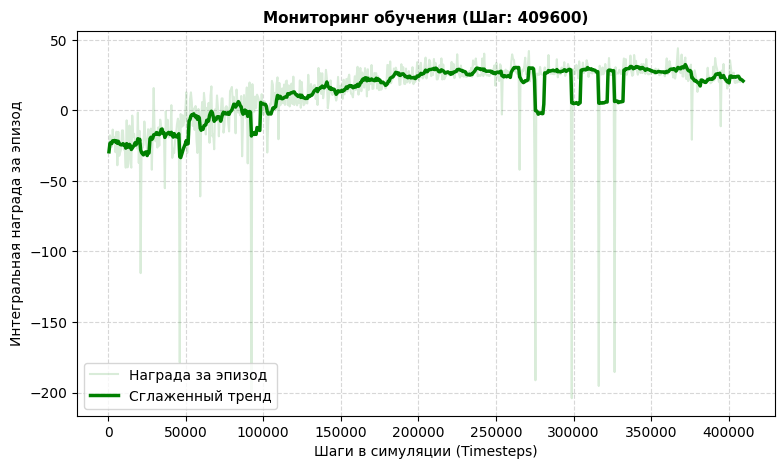

✅ Обучение для Case 3: Shielded PI-RL успешно завершено!
💾 Модель сохранена на диск: ./ppo_spacecraft_logs/case_3_shielded_pi_rl\case_3_shielded_pi_rl.zip

🎉 Все выбранные процессы обучения завершены!


In [16]:
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import EvalCallback

log_dir = "./ppo_spacecraft_logs/"
os.makedirs(log_dir, exist_ok=True)

print(f"Инициализация обучения. Фильтр активных задач: {CASES_TO_TRAIN}")

# Итерируемся по кейсам, выбранным в фильтре CASES_TO_TRAIN
for case_key in CASES_TO_TRAIN:
    if case_key not in GLOBAL_ENV_REGISTRY:
        print(f"⚠️ Ключ '{case_key}' не найден в глобальном реестре. Пропуск.")
        continue
        
    case_info = GLOBAL_ENV_REGISTRY[case_key]
    case_name = case_info["name"]
    EnvClass = case_info["class"]
    folder_name = case_info["folder"]
    
    print(f"\n🚀 Запуск обучения агента для: {case_name}...")
    
    # Создаем индивидуальный путь для логов
    case_sub_dir = os.path.join(log_dir, folder_name)
    os.makedirs(case_sub_dir, exist_ok=True)
    
    # Инициализация среды и логгера Monitor
    raw_env = EnvClass(config=SPACECRAFT_CONFIG, reward_config=REWARD_CONFIG)
    monitored_env = Monitor(raw_env, case_sub_dir)
    vec_env = DummyVecEnv([lambda: monitored_env])

    # 3. Инициализируем интерактивный колбэк
    # plot_freq=n_steps означает, что график будет перерисовываться при каждом обновлении буфера PPO
    plot_callback = RealTimePlottingCallback(log_dir=case_sub_dir, plot_freq=PPO_HYPERPARAMS["n_steps"], window=10)
    
    
    # Создаем отдельную среду для детерминированной оценки и сохранения лучших весов
    eval_raw_env = EnvClass(config=SPACECRAFT_CONFIG, reward_config=REWARD_CONFIG)
    eval_env = Monitor(eval_raw_env)

    eval_callback = EvalCallback(
        eval_env,
        best_model_save_path=case_sub_dir,  # Сохранит best_model.zip в папку кейса
        log_path=case_sub_dir,
        eval_freq=10240,                    # Оценка каждые 5 обновлений буфера PPO
        n_eval_episodes=5,                  # Усреднение по 5 случайным начальным ориентациям
        deterministic=True,
        render=False,
        verbose=0
    )

    # Инициализация модели PPO с распаковкой глобальных гиперпараметров
    model = PPO(
        env=vec_env,
        seed=42,
        **{k: v for k, v in PPO_HYPERPARAMS.items() if k != "policy_kwargs"}, # Защита от дублирования ключей
        policy_kwargs=policy_kwargs
    )
    
    # Запуск обучения
    model.learn(
        total_timesteps=TOTAL_TRAINING_TIMESTEPS,
        callback=[plot_callback, eval_callback]
    )
    print(f"✅ Обучение для {case_name} успешно завершено!")
    
    # Формирование уникального имени файла и сохранение на жесткий диск
    model_save_path = os.path.join(case_sub_dir, f"{folder_name}.zip")
    model.save(model_save_path)
    print(f"💾 Модель сохранена на диск: {model_save_path}")

print("\n🎉 Все выбранные процессы обучения завершены!")


### Графики кривых обучения

Построение графиков из диска. Активный фильтр отрисовки: ['case_1', 'case_2', 'case_3']


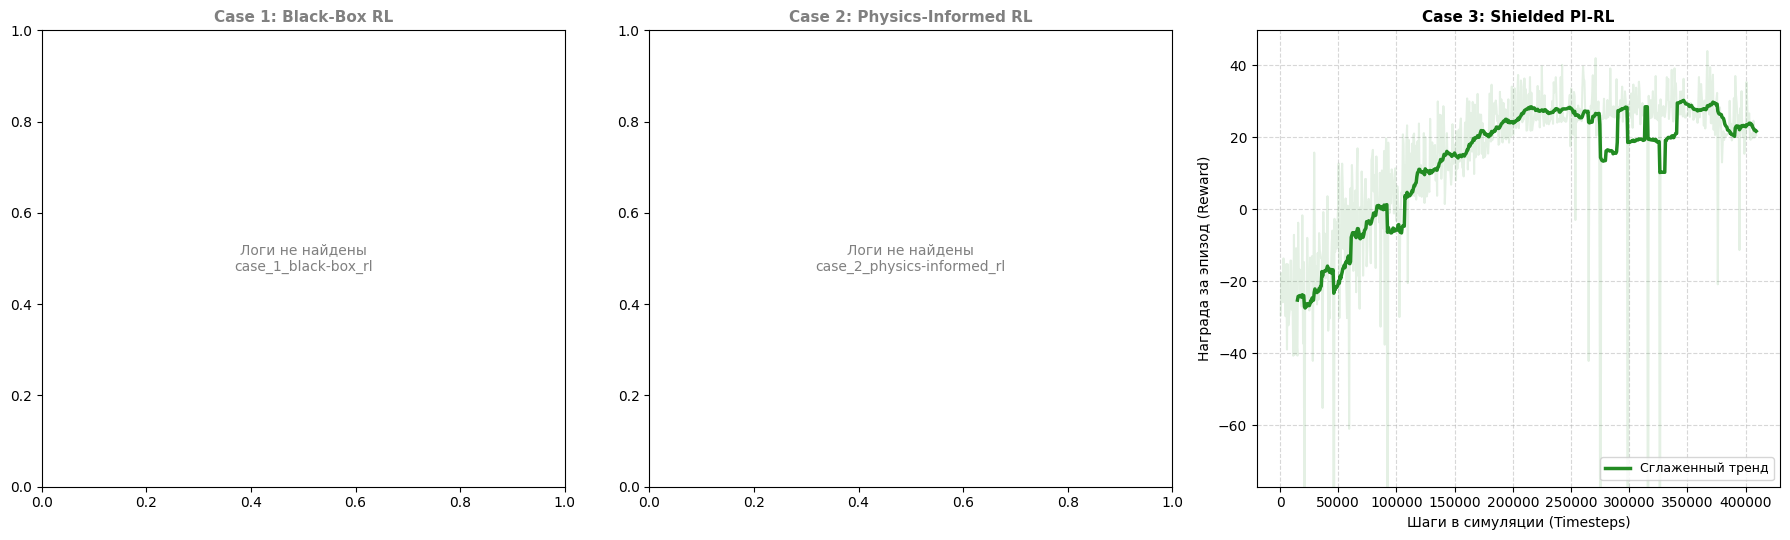

🎉 Графики успешно обновлены в файле 'rl_curves_filtered_panels.png'.


In [51]:
from stable_baselines3.common.results_plotter import load_results, ts2xy

log_dir = "./ppo_spacecraft_logs/"
window_size = 25  # Окно сглаживания тренда

# Фильтруем реестр: берем только те кейсы, которые указаны в CASES_TO_PLOT и реально существуют
active_plot_keys = [k for k in CASES_TO_PLOT if k in GLOBAL_ENV_REGISTRY]
num_plots = len(active_plot_keys)

if num_plots == 0:
    raise ValueError("❌ Список CASES_TO_PLOT пуст или содержит несуществующие ключи.")

# Динамически настраиваем размер сетки графиков в зависимости от количества выбранных кейсов
fig, axes = plt.subplots(1, num_plots, figsize=(6 * num_plots, 5.5), squeeze=False)
axes = axes.flatten()  # Гарантируем одномерный массив осей для итерации

print(f"Построение графиков из диска. Активный фильтр отрисовки: {active_plot_keys}")

for i, case_key in enumerate(active_plot_keys):
    case_info = GLOBAL_ENV_REGISTRY[case_key]
    case_name = case_info["name"]
    folder_name = case_info["folder"]
    color = case_info["color"]
    ax = axes[i]
    
    case_path = os.path.join(log_dir, folder_name)
    
    if not os.path.exists(case_path):
        ax.text(0.5, 0.5, f"Логи не найдены\n{folder_name}", ha='center', va='center', color='gray')
        ax.set_title(case_name, fontsize=11, fontweight="bold", color='gray')
        continue
        
    try:
        # Чтение Monitor.csv с жесткого диска
        x, y = ts2xy(load_results(case_path), 'timesteps')
        
        if len(y) >= window_size:
            # Расчет скользящего среднего
            y_smoothed = np.convolve(y, np.ones(window_size)/window_size, mode='valid')
            x_smoothed = x[len(x) - len(y_smoothed):]
            
            # Визуализация сырых данных и сглаженного тренда
            ax.plot(x, y, color=color, alpha=0.12)
            ax.plot(x_smoothed, y_smoothed, color=color, linewidth=2.5, label="Сглаженный тренд")
            
            # Адаптивное вычисление масштаба оси Y по перцентилям
            y_min_adaptive = np.percentile(y, 1.0)
            y_max_adaptive = np.max(y)
            y_range = y_max_adaptive - y_min_adaptive
            if y_range > 0:
                ax.set_ylim(y_min_adaptive - 0.05 * y_range, y_max_adaptive + 0.05 * y_range)
        elif len(y) > 0:
            ax.plot(x, y, color=color, linewidth=1.5, label="Сырые данные")
        else:
            ax.text(0.5, 0.5, "Файл лога пуст", ha='center', va='center', color='gray')
        
        # Стилизация субплота
        ax.set_title(case_name, fontsize=11, fontweight="bold")
        ax.set_xlabel("Шаги в симуляции (Timesteps)", fontsize=10)
        ax.set_ylabel("Награда за эпизод (Reward)", fontsize=10)
        ax.grid(True, linestyle="--", alpha=0.5)
        ax.legend(loc="lower right", fontsize=9)
        
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка чтения логов\n{str(e)}", ha='center', va='center', color='crimson')
        ax.set_title(case_name, fontsize=11, fontweight="bold", color='crimson')

plt.tight_layout()
# plt.savefig("rl_curves_filtered_panels.png", dpi=300, bbox_inches="tight")
plt.show()

print("🎉 Графики успешно обновлены в файле 'rl_curves_filtered_panels.png'.")


## 6: Проверка обученных моделей и анализ переходных процессов КА
Тестирование качества управления одной из обученных нейросетей PPO в детерминированном режиме (`deterministic=True`). 

Для смены анализируемого сценария достаточно изменить значение управляющей переменной `CHOSEN_CASE` в диапазоне от `1` до `3`. Скрипт самостоятельно:
1. Выберет соответствующий класс физической среды (`Case1`, `Case2` или `Case3`).
2. Автоматически сформирует корректный путь к zip-архиву с обученными весами модели.
3. Запустит демонстрационный маневр разворота и стабилизации КА из случайного начального положения.
4. Отрисует 4 синхронизированных во времени графика переходных процессов бортовой телеметрии: изменение компонентов кватерниона рассогласования, угловые скорости КА, управляющие моменты и накопление оборотов двигателей-маховиков.


📂 Запрос на чтение модели через реестр: ./ppo_spacecraft_logs/case_3_shielded_pi_rl\best_model.zip
✅ Успешная загрузка. Нейросеть ожидает входной вектор размерностью: 8
🚀 Запуск симуляции полета выбранного агента...
⏹️ Симуляция завершена на 749-м шаге. Флаги: terminated=False, truncated=True
✅ Данные собраны. Построение графиков...


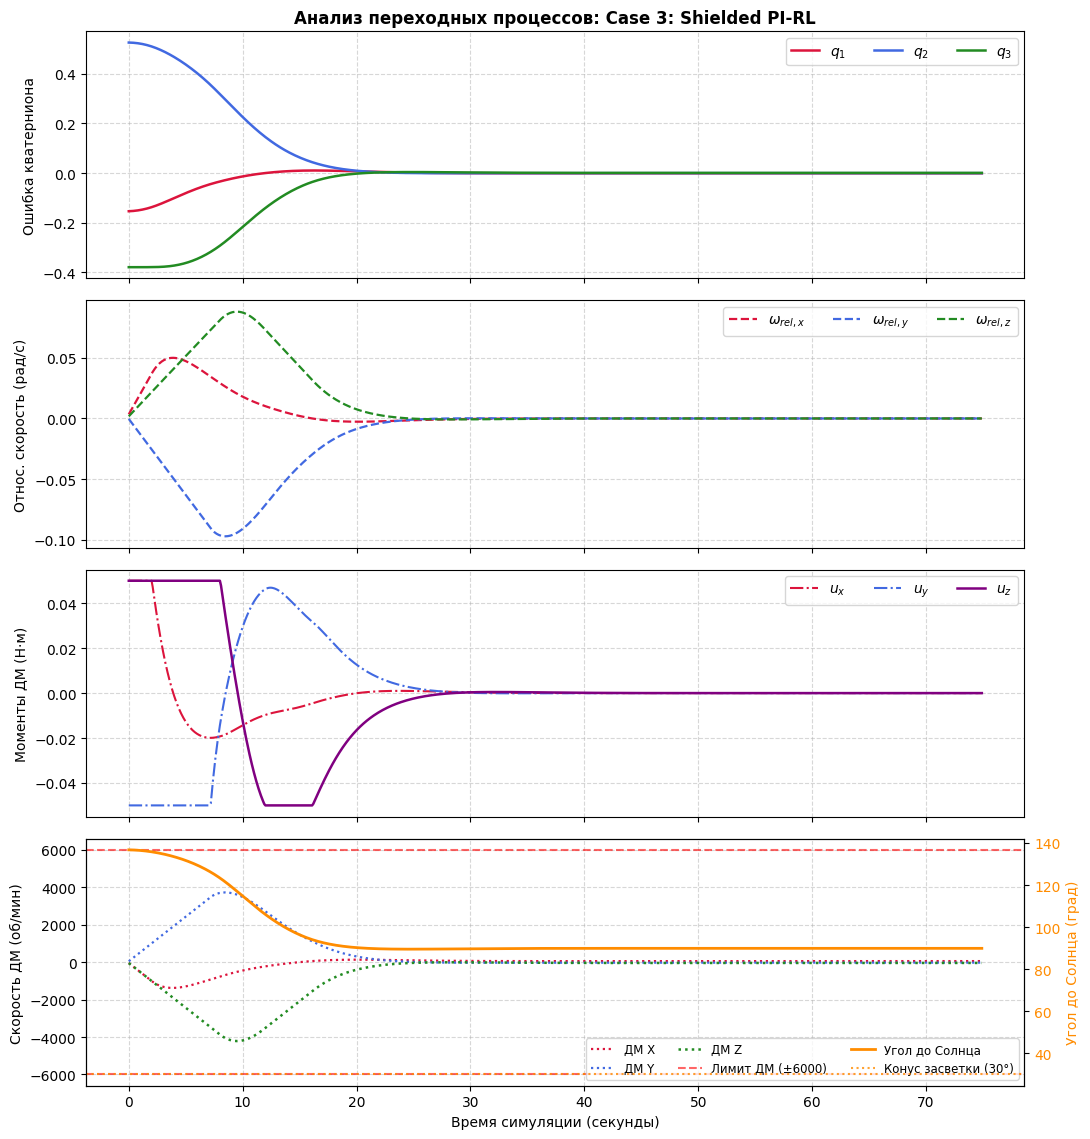


📋 Финальные метрики стабильности для Case 3: Shielded PI-RL:
 -> Модуль ошибки кватерниона: 0.00124 (угол: 0.14°)
 -> Модуль относительной скорости: 0.00000 рад/с
 -> Минимальный угол до Солнца: 89.54°


In [54]:
# =====================================================================
# 1. ЗАГРУЗКА МОДЕЛИ С ДИСКА ЧЕРЕЗ ГЛОБАЛЬНЫЙ РЕЕСТР НАСТРОЕК
# =====================================================================
CHOSEN_CASE_KEY = "case_3"  # "case_1" | "case_2" | "case_3"
LOAD_BEST = True            # True -> best_model.zip, False -> финальная {folder_name}.zip

case_info = GLOBAL_ENV_REGISTRY[CHOSEN_CASE_KEY]
SELECTED_ENV_CLASS = case_info["class"]
CHOSEN_CASE = case_info["name"]
folder_name = case_info["folder"]

log_dir = "./ppo_spacecraft_logs/"
filename = "best_model.zip" if LOAD_BEST else f"{folder_name}.zip"
model_disk_path = os.path.join(log_dir, folder_name, filename)

print(f"📂 Запрос на чтение модели через реестр: {model_disk_path}")
if not os.path.exists(model_disk_path):
    raise FileNotFoundError(f"❌ Файл весов не найден по пути {model_disk_path}. Проверьте фильтры обучения!")

LOADED_MODEL = PPO.load(model_disk_path)
expected_shape = LOADED_MODEL.observation_space.shape[0]
print(f"✅ Успешная загрузка. Нейросеть ожидает входной вектор размерностью: {expected_shape}")

# =====================================================================
# 2. ЗАПУСК СРЕДЫ ЧЕРЕЗ ШТАТНЫЙ RESET С ФИКСИРОВАННЫМ SEED
# =====================================================================
validation_config = SPACECRAFT_CONFIG.copy()
validation_config["max_episode_steps"] = 750  # 75 секунд симуляции

test_env = SELECTED_ENV_CLASS(config=validation_config, reward_config=REWARD_CONFIG)
obs, _ = test_env.reset(seed=42)

# Гарантируем нулевые начальные обороты маховиков
test_env.wheel_speeds = np.zeros(3, dtype=np.float64)
obs = test_env._get_obs()

# =====================================================================
# 3. СБОР ФИЗИЧЕСКОЙ ТЕЛЕМЕТРИИ
# =====================================================================
time_hist = []
q_components_hist = []
omega_rel_components_hist = []
applied_moments_hist = []
wheel_speeds_rpm_hist = []
angle_sun_hist = []
filter_active_hist = []

print("🚀 Запуск симуляции полета выбранного агента...")

for step in range(validation_config["max_episode_steps"]):
    action, _ = LOADED_MODEL.predict(obs, deterministic=True)
    next_obs, reward, terminated, truncated, info = test_env.step(action)
    
    # --- ИЗВЛЕЧЕНИЕ ЧЕСТНЫХ ФИЗИЧЕСКИХ ВЕЛИЧИН (ЕДИНООБРАЗНО ДЛЯ ВСЕХ CASE) ---
    q_curr = test_env.state[0:4].copy()
    if hasattr(test_env, "_get_relative_elements"):
        _, omega_rel = test_env._get_relative_elements()
    else:
        omega_orb_B = rotate_vector_by_quat(np.array([0.0, test_env.mean_motion, 0.0]), quat_conjugate(q_curr))
        omega_rel = test_env.state[4:7] - omega_orb_B
    
    # Угол между оптической осью датчика и направлением на Солнце
    sun_B = rotate_vector_by_quat(validation_config["sun_vector_N"], quat_conjugate(q_curr))
    sun_B_norm = sun_B / np.linalg.norm(sun_B)
    angle_deg = np.degrees(np.arccos(np.clip(np.dot(validation_config["sensor_axis_B"], sun_B_norm), -1.0, 1.0)))
    
    # Фактически приложенное управление и статус фильтра
    applied_action = info.get("applied_action", action)
    is_filter_active = info.get("filter_activated", False)
    
    # Обороты роторов ДМ (перевод из рад/с в об/мин)
    wheel_speeds_rpm = test_env.wheel_speeds.copy() * (60.0 / (2.0 * np.pi))
    
    time_hist.append(step * validation_config["dt"])
    q_components_hist.append(q_curr[1:4])
    omega_rel_components_hist.append(omega_rel.copy())
    applied_moments_hist.append(applied_action * validation_config["max_u_torque"])
    wheel_speeds_rpm_hist.append(wheel_speeds_rpm)
    angle_sun_hist.append(angle_deg)
    filter_active_hist.append(1.0 if is_filter_active else 0.0)
    
    obs = next_obs
    if terminated or truncated:
        print(f"⏹️ Симуляция завершена на {step}-м шаге. Флаги: terminated={terminated}, truncated={truncated}")
        break

q_components_hist = np.array(q_components_hist)
omega_rel_components_hist = np.array(omega_rel_components_hist)
applied_moments_hist = np.array(applied_moments_hist)
wheel_speeds_rpm_hist = np.array(wheel_speeds_rpm_hist)
filter_mask = np.array(filter_active_hist) > 0

print("✅ Данные собраны. Построение графиков...")

# =====================================================================
# 4. ПОСТРОЕНИЕ 4 СИНХРОНИЗИРОВАННЫХ ГРАФИКОВ
# =====================================================================
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(11, 11.5), sharex=True)

# Окно 1: Компоненты векторной части кватерниона ошибки
ax1.plot(time_hist, q_components_hist[:, 0], label=r"$q_1$", color="crimson", linewidth=1.8)
ax1.plot(time_hist, q_components_hist[:, 1], label=r"$q_2$", color="royalblue", linewidth=1.8)
ax1.plot(time_hist, q_components_hist[:, 2], label=r"$q_3$", color="forestgreen", linewidth=1.8)
ax1.set_ylabel("Ошибка кватерниона")
ax1.set_title(f"Анализ переходных процессов: {CHOSEN_CASE}", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper right", ncol=3)

# Окно 2: Относительная угловая скорость корпуса КА (честные рад/с)
ax2.plot(time_hist, omega_rel_components_hist[:, 0], color="crimson", linestyle="--", linewidth=1.6, label=r"$\omega_{rel, x}$")
ax2.plot(time_hist, omega_rel_components_hist[:, 1], color="royalblue", linestyle="--", linewidth=1.6, label=r"$\omega_{rel, y}$")
ax2.plot(time_hist, omega_rel_components_hist[:, 2], color="forestgreen", linestyle="--", linewidth=1.6, label=r"$\omega_{rel, z}$")
ax2.set_ylabel("Относ. скорость (рад/с)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper right", ncol=3)

# Окно 3: Фактически приложенные управляющие моменты ДМ (Н·м)
ax3.plot(time_hist, applied_moments_hist[:, 0], color="crimson", linestyle="-.", linewidth=1.5, label=r"$u_x$")
ax3.plot(time_hist, applied_moments_hist[:, 1], color="royalblue", linestyle="-.", linewidth=1.5, label=r"$u_y$")
ax3.plot(time_hist, applied_moments_hist[:, 2], color="purple", linestyle="-", linewidth=1.8, label=r"$u_z$")
if np.any(filter_mask):
    ax3.fill_between(time_hist, -validation_config["max_u_torque"], validation_config["max_u_torque"],
                     where=filter_mask, color="orange", alpha=0.15, label="Работа щита")
ax3.set_ylabel("Моменты ДМ (Н·м)")
ax3.grid(True, linestyle="--", alpha=0.5)
ax3.legend(loc="upper right", ncol=4)

# Окно 4: Обороты ДМ (левая ось) + Угол до Солнца (правая ось)
l1 = ax4.plot(time_hist, wheel_speeds_rpm_hist[:, 0], color="crimson", linestyle=":", linewidth=1.6, label="ДМ X")
l2 = ax4.plot(time_hist, wheel_speeds_rpm_hist[:, 1], color="royalblue", linestyle=":", linewidth=1.6, label="ДМ Y")
l3 = ax4.plot(time_hist, wheel_speeds_rpm_hist[:, 2], color="forestgreen", linestyle=":", linewidth=1.8, label="ДМ Z")
l4 = ax4.axhline(y=validation_config["max_wheel_speed_rpm"], color="red", linestyle="--", alpha=0.6, label="Лимит ДМ (±6000)")
ax4.axhline(y=-validation_config["max_wheel_speed_rpm"], color="red", linestyle="--", alpha=0.6)
ax4.set_ylabel("Скорость ДМ (об/мин)")
ax4.set_xlabel("Время симуляции (секунды)")
ax4.grid(True, linestyle="--", alpha=0.5)

ax4_twin = ax4.twinx()
l5 = ax4_twin.plot(time_hist, angle_sun_hist, color="darkorange", linewidth=2.0, label="Угол до Солнца")
l6 = ax4_twin.axhline(y=validation_config["exclusion_cone_angle_deg"], color="darkorange", linestyle=":", alpha=0.8, label="Конус засветки (30°)")
ax4_twin.set_ylabel("Угол до Солнца (град)", color="darkorange")
ax4_twin.tick_params(axis="y", labelcolor="darkorange")

# Объединенная легенда для обеих осей 4-го графика
lines = l1 + l2 + l3 + [l4] + l5 + [l6]
labels = [l.get_label() for l in lines]
ax4.legend(lines, labels, loc="lower right", ncol=3, fontsize=8.5)

plt.tight_layout()
plt.show()

final_angle_err = 2.0 * np.degrees(np.arcsin(np.clip(np.linalg.norm(q_components_hist[-1]), 0.0, 1.0)))
print(f"\n📋 Финальные метрики стабильности для {CHOSEN_CASE}:")
print(f" -> Модуль ошибки кватерниона: {np.linalg.norm(q_components_hist[-1]):.5f} (угол: {final_angle_err:.2f}°)")
print(f" -> Модуль относительной скорости: {np.linalg.norm(omega_rel_components_hist[-1]):.5f} рад/с")
print(f" -> Минимальный угол до Солнца: {min(angle_sun_hist):.2f}°")


### Тестовые сценарии для проверки выученной стратегии управления

Статистическое усреднение награды по случайным эпизодам из `reset()` не гарантирует работоспособности системы управления в редких, но критически важных нештатных ситуациях. Для комплексной проверки синтезированного регулятора (`Case 3`) проводятся испытания на **четырёх эталонных граничных сценариях**:

1. **Идеальный надир ($\theta_0 = 0^\circ, \; \Delta\boldsymbol{\omega}_0 = \mathbf{0}$):**
   * *Цель теста:* Проверка точности удержания положения равновесия. Позволяет убедиться в отсутствии статической ошибки наведения, высокочастотного «дребезга» приводов (chattering) и паразитных управляющих моментов в окрестности нуля.
2. **Разворот на $180^\circ$ ($\theta_0 = 180^\circ, \; \Delta\boldsymbol{\omega}_0 = \mathbf{0}$):**
   * *Цель теста:* Проверка выхода из **топологической седловой точки** группы вращений $SO(3)$, где градиент гладкого потенциала $V_q \propto (1 - q_0^2)$ обращается в ноль. Предельный угол переброски также выводит маховики в режим глубокого насыщения по кинетическому моменту, проверяя способность системы управления своевременно начинать торможение.
3. **Попутное возмущение ($\theta_0 = 90^\circ, \; \Delta\boldsymbol{\omega}_0 = [0.02, -0.02, 0.02]^T\text{ рад/с}$):**
   * *Цель теста:* Имитация начальной многоосной закрутки ($\|\Delta\boldsymbol{\omega}_0\| \approx 0.035\text{ рад/с}$). Проверяет качество апериодического демпфирования ($\zeta_{\text{eff}} \approx 1.0$) и отсутствие затяжного перерегулирования при ненулевой начальной кинетической энергии.
4. **Стресс-кувырок к Солнцу ($\theta_0 = 45^\circ, \; \Delta\boldsymbol{\omega}_0 = [0, 0, 0.05]^T\text{ рад/с}$ в сторону запретного конуса):**
   * *Цель теста:* Прямая проверка **архитектуры безопасного управления (Safe PI-RL)**. Аппарат стартует в непосредственной близости от зоны исключения (угол до Солнца $\theta_{\text{sun}} = 45^\circ$) с высокой угловой скоростью ($\|\Delta\boldsymbol{\omega}_0\| = 0.05\text{ рад/с} \approx 2.86^\circ/\text{с}$), направленной прямо в запретный конус ($30^\circ$). Тест оценивает корректность перехвата управления предиктивным фильтром, удержание границы безопасности и безударный возврат управления нейросети после отвода оптической оси.


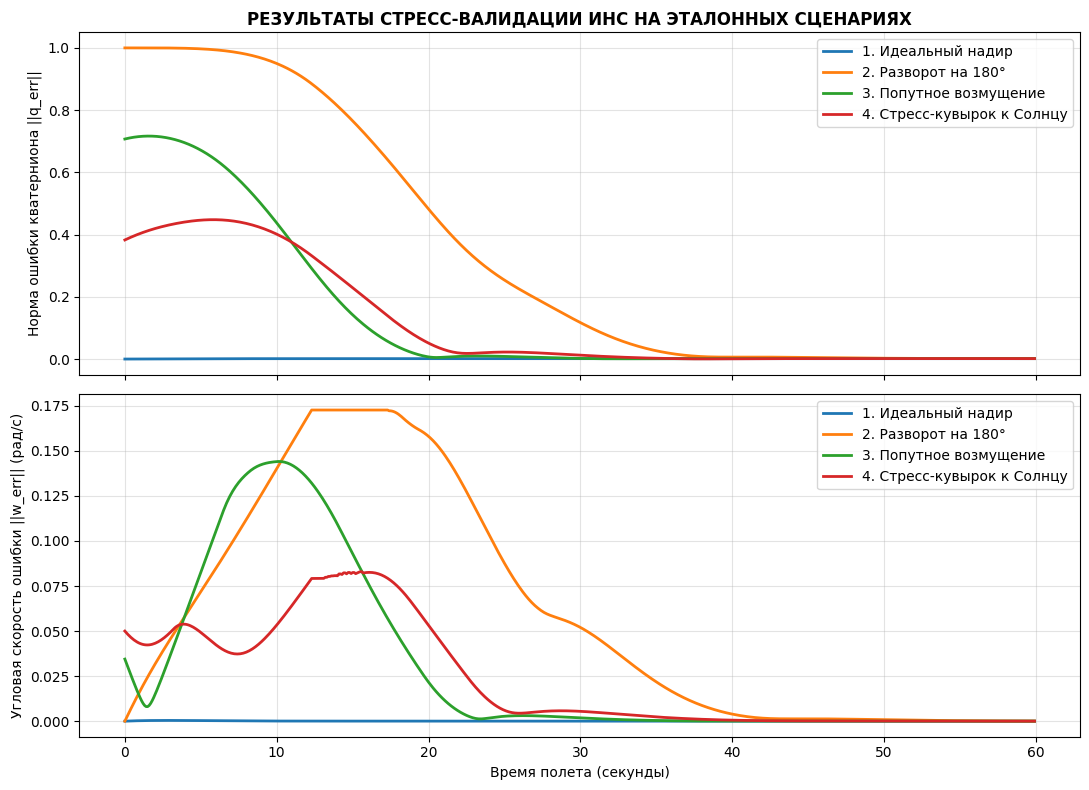

,Нач. угол (°),"T_уст (<5.0°), с",Ош. угла уст. (°),Ош. ω уст. (рад/с),Пик ω (рад/с),Затраты ∫||a||²dt,Мин. угол Солнца (°),Работа щита (шагов)
Сценарий,,,,,,,,
1. Идеальный надир,0.0,0.0,0.14,0.00000,0.000,0.00,89.9,0
2. Разворот на 180°,180.0,33.7,0.16,0.00014,0.173,47.26,89.7,50
3. Попутное возмущение,90.0,17.9,0.16,0.00000,0.144,43.42,57.2,0
4. Стресс-кувырок к Солнцу,45.0,20.4,0.16,0.00002,0.083,32.26,38.2,17


In [53]:
# 1. Загрузка лучшей обученной модели
CHOSEN_CASE_KEY = "case_3"
case_info = GLOBAL_ENV_REGISTRY[CHOSEN_CASE_KEY]
SELECTED_ENV_CLASS = case_info["class"]
folder_name = case_info["folder"]

model_path = os.path.join("./ppo_spacecraft_logs/", folder_name, "best_model.zip")
best_model = PPO.load(model_path)

val_env = SELECTED_ENV_CLASS(config=SPACECRAFT_CONFIG, reward_config=REWARD_CONFIG)

# 2. Функция расчёта метрик качества переходного процесса
def evaluate_scenario_metrics(history, dt=0.1, angle_tol_deg=5.0):
    q_norms = np.array(history["q_err_norm"])
    w_norms = np.array(history["w_err_norm"])
    actions = np.array(history["action"])
    sun_angles = np.array(history["sun_angle_deg"])
    shield_flags = np.array(history["filter_activated"])
    
    # Переводим норму векторной части кватерниона в полный угол ошибки (градусы)
    angles_deg = 2.0 * np.degrees(np.arcsin(np.clip(q_norms, 0.0, 1.0)))
    times = np.arange(len(angles_deg)) * dt
    
    # Извлекаем массив индексов через [0]
    outside_idx = np.where(angles_deg > angle_tol_deg)[0]
    if len(outside_idx) == 0:
        settling_time = 0.0
    elif outside_idx[-1] == len(angles_deg) - 1:
        settling_time = np.nan
    else:
        settling_time = times[outside_idx[-1] + 1]
        
    # Установившиеся ошибки (усреднение по последним 5 секундам)
    tail_steps = min(50, len(angles_deg))
    steady_angle_deg = float(np.mean(angles_deg[-tail_steps:]))
    steady_omega_rad = float(np.mean(w_norms[-tail_steps:]))
    
    return {
        "Нач. угол (°)": round(float(angles_deg[0]), 1),
        f"T_уст (<{angle_tol_deg}°), с": f"{settling_time:.1f}" if not np.isnan(settling_time) else f"> {times[-1]:.0f}.0",
        "Ош. угла уст. (°)": round(steady_angle_deg, 2),
        "Ош. ω уст. (рад/с)": f"{steady_omega_rad:.5f}",
        "Пик ω (рад/с)": round(float(np.max(w_norms)), 3),
        "Затраты ∫||a||²dt": round(float(np.sum(np.sum(actions**2, axis=1)) * dt), 2),
        "Мин. угол Солнца (°)": round(float(np.min(sun_angles)), 1),
        "Работа щита (шагов)": int(np.sum(shield_flags))
    }

# 3. Определение 4 эталонных стресс-сценариев
def make_quat(axis, angle_deg):
    rad = np.radians(angle_deg)
    axis = np.array(axis, dtype=np.float64)
    axis /= np.linalg.norm(axis)
    return np.concatenate([[np.cos(rad / 2.0)], axis * np.sin(rad / 2.0)])

# Вектор Солнца из конфига (чтобы построить траекторию вблизи запретного конуса 30°)
sun_dir = np.array(SPACECRAFT_CONFIG["sun_vector_N"], dtype=np.float64)
sun_dir /= np.linalg.norm(sun_dir)
ortho_axis = np.cross(sun_dir, [0.0, 0.0, 1.0])
if np.linalg.norm(ortho_axis) < 1e-3:
    ortho_axis = np.cross(sun_dir, [1.0, 0.0, 0.0])

test_scenarios = {
    "1. Идеальный надир": {
        "q_init": np.array([1.0, 0.0, 0.0, 0.0]),
        "w_offset": np.array([0.0, 0.0, 0.0])
    },
    "2. Разворот на 180°": {
        "q_init": make_quat([0.0, 1.0, 0.0], 180.0),
        "w_offset": np.array([0.0, 0.0, 0.0])
    },
    "3. Попутное возмущение": {
        "q_init": make_quat([0.5, -0.5, 0.7], 90.0),
        "w_offset": np.array([0.02, -0.02, 0.02])
    },
    "4. Стресс-кувырок к Солнцу": {
        # Старт на расстоянии 45° от Солнца (поворот вокруг Z на +45°)
        # + высокая начальная скорость +0.05 рад/с прямо в запретный конус 30°
        "q_init": make_quat([0.0, 0.0, 1.0], 45.0),
        "w_offset": np.array([0.0, 0.0, 0.05])
    }
}

# 4. Прогон симуляции и сбор данных
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
summary_rows = []
omega_orb = np.array([0.0, val_env.mean_motion, 0.0], dtype=np.float64)

for name, params in test_scenarios.items():
    val_env.reset(seed=42)
    val_env.state = np.concatenate([params["q_init"], omega_orb + params["w_offset"]]).astype(np.float64)
    obs = val_env._get_obs()
    
    history = {
        "times": [], "q_err_norm": [], "w_err_norm": [],
        "action": [], "sun_angle_deg": [], "filter_activated": []
    }
    
    for step in range(val_env.max_steps):
        q_err, w_rel = val_env._get_relative_elements()
        history["times"].append(step * val_env.config["dt"])
        history["q_err_norm"].append(np.linalg.norm(q_err[1:4]))
        history["w_err_norm"].append(np.linalg.norm(w_rel))
        
        sun_B = rotate_vector_by_quat(val_env.config["sun_vector_N"], quat_conjugate(val_env.state[0:4]))
        cos_sun = np.clip(np.dot(val_env.config["sensor_axis_B"], sun_B / np.linalg.norm(sun_B)), -1.0, 1.0)
        history["sun_angle_deg"].append(np.degrees(np.arccos(cos_sun)))
        
        action, _ = best_model.predict(obs, deterministic=True)
        obs, _, terminated, truncated, info = val_env.step(action)
        
        history["action"].append(info.get("applied_action", action))
        history["filter_activated"].append(info.get("filter_activated", False))
        
        if terminated or truncated:
            break
            
    ax1.plot(history["times"], history["q_err_norm"], linewidth=2.0, label=name)
    ax2.plot(history["times"], history["w_err_norm"], linewidth=2.0, label=name)
    
    metrics = evaluate_scenario_metrics(history, dt=val_env.config["dt"], angle_tol_deg=5.0)
    metrics["Сценарий"] = name
    summary_rows.append(metrics)

# 5. Оформление графиков и вывод сводной таблицы
ax1.set_title("РЕЗУЛЬТАТЫ ПРОВЕРОК НА ЭТАЛОННЫХ СЦЕНАРИЯХ", fontweight="bold", fontsize=12)
ax1.set_ylabel("Норма ошибки кватерниона ||q_err||", fontsize=10)
ax1.grid(True, alpha=0.35)
ax1.legend(loc="upper right")

ax2.set_ylabel("Угловая скорость ошибки ||w_err|| (рад/с)", fontsize=10)
ax2.set_xlabel("Время полета (секунды)", fontsize=10)
ax2.grid(True, alpha=0.35)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

df_summary = pd.DataFrame(summary_rows).set_index("Сценарий")
display(df_summary)


## Заключение и направления дальнейшего развития модели
Для дальнейшего приближения математической модели к реальным условиям эксплуатации космического аппарата (КА) на орбите выделены следующие направления доработки:

### 1. Уточнение орбитальной и внешней физической среды
* **Динамическая эфемеридная модель Солнца:** Отказ от задания вектора на Солнце $\mathbf{s}$ как константы в орбитальных осях. Переход к расчёту положения Солнца в инерциальной системе координат (ИСК) с последующим преобразованием в ОСК и ССК по мере движения КА по орбите.
* **Переход к эллиптическим орбитам:** Отказ от кругового приближения ($n = \text{const}$). Внедрение уравнений кеплерова движения с переменными орбитальной скоростью $\boldsymbol{\omega}_{orb}(t)$, угловым ускорением $\dot{\boldsymbol{\omega}}_{orb}(t)$ и расстоянием до центра Земли $r(t)$ (влияющим на величину гравитационного момента $\mathbf{M}_{grav} \propto 1/r^3$).
* **Модель аэродинамического момента:** Добавление расчёта возмущающего момента от взаимодействия корпуса КА и солнечных панелей с верхней атмосферой Земли на низких околоземных орбитах (НОО) с учётом смещения центра давления относительно центра масс.

### 2. Детализация модели исполнительных органов (ДМ)
* **Поканальный учёт насыщения и информирование агента:** Замена общего флага фильтра на раздельную поканальную обработку насыщения двигателей-маховиков (блокировка только разгона при превышении порога $\Omega_{\max}$ с сохранением возможности торможения). Добавление текущих нормированных скоростей роторов $\tilde{\boldsymbol{\Omega}} = \boldsymbol{\Omega}/\Omega_{\max}$ и раздельных индикаторов срабатывания щитов ($f_{\text{sun}}, \mathbf{f}_{\text{wheel}}$) в вектор наблюдений для обеспечения полной марковости.


### 3. Расширение функциональности и робастности системы управления
* **Произвольная целевая ориентация и программное слежение:** Переход от стабилизации исключительно в орбитальной СК к задаче переориентации в произвольное заданное угловое положение $\mathbf{q}_{\text{target}}$ (в ИСК или ОСК), а также отслеживание программных траекторий наведения $\mathbf{q}_{\text{ref}}(t), \boldsymbol{\omega}_{\text{ref}}(t)$.
* **Множественные запретные конусы (CBF-QP):** Обобщение предиктивного фильтра безопасности на случай одновременного учёта нескольких динамических зон исключения (Солнце, альбедо Земли, Луна) на основе барьерных функций управления (Control Barrier Functions).
* **Робастность и адаптация (Domain Randomization):** Внедрение неопределённости тензора инерции $\mathbf{J}_B$, шумов и задержек бортовых датчиков (звёздный датчик, ДУС), а также тестирование отказоустойчивости стратегии при деградации одного из маховиков.
* **Управление КА с упругими элементами конструкции:** Переход от модели абсолютно твёрдого тела к гибридной модели «жёсткий центральный корпус + упругие панели солнечных батарей / антенны» с использованием модальных координат. Обучение агента (и настройка предиктивного фильтра) активному демпфированию упругих колебаний без возбуждения резонансных частот конструкции при быстрых разворотах.


## Приложение А. Обоснование эквивалентности вознаграждения на основе функции Ляпунова и задачи LQR

Покажем, как максимизация дисконтированной суммы вознаграждений в среде `Case 3` сводится к решению классической линейно-квадратичной задачи оптимального управления (LQR) в окрестности положения равновесия.

### 1. Преобразование Абеля для телескопической награды

Полная дисконтированная сумма наград (Return) на бесконечном горизонте имеет вид:
$$G_0 = \sum_{t=0}^{\infty} \gamma^t R_t = \sum_{t=0}^{\infty} \gamma^t \Big[ S_V (V_t - V_{t+1}) + r_{\text{bonus}}(V_t) - w_u \|\mathbf{a}_t\|^2 \Big]$$
*(Примечание: индикатор срабатывания щита безопасности $\mathbb{I}_{\text{shield}} = 0$ в окрестности целевого положения равновесия, поэтому в локальном анализе он не участвует).*

Рассмотрим отдельно сумму телескопических слагаемых (дискретное интегрирование по частям — преобразование Абеля):
$$\sum_{t=0}^{N} \gamma^t S_V (V_t - V_{t+1}) = S_V \left( V_0 + \sum_{t=1}^{N} \gamma^t V_t - \sum_{t=0}^{N-1} \gamma^t V_{t+1} - \gamma^N V_{N+1} \right)$$

Выполнив сдвиг индекса во второй сумме ($k = t + 1$), получим:
$$\sum_{t=0}^{N} \gamma^t S_V (V_t - V_{t+1}) = S_V \left( V_0 + \sum_{t=1}^{N} \gamma^t V_t - \sum_{k=1}^{N} \gamma^{k-1} V_k - \gamma^N V_{N+1} \right) = S_V V_0 - S_V \left(\frac{1}{\gamma} - 1\right) \sum_{t=1}^{N} \gamma^t V_t - S_V \gamma^N V_{N+1}$$

При $N \to \infty$ (учитывая ограниченность потенциала $V_t$ и условие $\gamma < 1$, откуда $\gamma^N V_{N+1} \to 0$), а также с точностью до множителя $1/\gamma \approx 1$ при $\gamma = 0.997$, приходим к выражению:
$$\sum_{t=0}^{\infty} \gamma^t S_V (V_t - V_{t+1}) \approx S_V V_0 - (1 - \gamma) S_V \sum_{t=0}^{\infty} \gamma^t V_t$$

Поскольку начальное состояние $S_V V_0$ не зависит от стратегии управления $\pi$, максимизация $G_0$ эквивалентна минимизации дисконтированного функционала затрат:
$$\mathcal{J} = \sum_{t=0}^{\infty} \gamma^t \Big[ (1 - \gamma) S_V V_t - r_{\text{bonus}}(V_t) + w_u \|\mathbf{a}_t\|^2 \Big] \longrightarrow \min_{\mathbf{a}_t}$$

---

### 2. Квадратичная аппроксимация в окрестности равновесия

Рассмотрим одноосное вращательное движение вокруг главной оси инерции с моментом $J$ при малых углах отклонения ($\theta \ll 1$, $\omega \ll 1$). Скалярная часть кватерниона ошибки равна $q_0 = \cos(\theta/2)$, откуда:
$$1 - q_0^2 = \sin^2\left(\frac{\theta}{2}\right) \approx \frac{\theta^2}{4}$$

Подставляя это в функцию Ляпунова, получаем её квадратичную форму:
$$V(\theta, \omega) = \frac{1}{2} k_\omega^{\text{RL}} \omega^2 + 2 k_q \left(1 - q_0^2\right) \approx \frac{1}{2} k_\omega^{\text{RL}} \omega^2 + \frac{1}{2} k_q \theta^2$$

Теперь разложим в ряд Тейлора экспоненциальный бонус стабилизации $r_{\text{bonus}}(V) = w_{\text{bonus}} \left( w_{\text{wide}} e^{-\alpha_{\text{wide}} V} + w_{\text{sharp}} e^{-\alpha_{\text{sharp}} V} \right)$. В зоне доводки ($\theta \in [5^\circ, 20^\circ]$), где формируется характер переходного процесса, узкий пик уже затух ($e^{-\alpha_{\text{sharp}} V} \approx 0$), а широкая воронка допускает разложение $e^{-\alpha_{\text{wide}} V} \approx 1 - \alpha_{\text{wide}} V$:
$$r_{\text{bonus}}(V) \approx \text{const} - \underbrace{\left(w_{\text{bonus}} w_{\text{wide}} \alpha_{\text{wide}}\right)}_{c_{\text{bonus}}} V$$

Подставляя $V$ и $r_{\text{bonus}}(V)$ в функционал затрат $\mathcal{J}$ и отбрасывая аддитивные константы, объединяем коэффициенты при потенциале $V_t$:
$$\mathcal{J} = \sum_{t=0}^{\infty} \gamma^t \Big[ c_V V_t + w_u a_t^2 \Big], \qquad \text{где } c_V = (1 - \gamma) S_V + c_{\text{bonus}}$$

---

### 3. Переход к непрерывной задаче LQR

Учитывая связь между безразмерной командой и физическим управляющим моментом $a_t = u_t / u_{\max}$, а также переходя при малом шаге $\Delta t = 0.1\text{ с}$ и $\gamma \to 1$ от суммы к интегралу (деление функционала на $\Delta t$ не меняет оптимального управления):
$$\mathcal{J}_{\text{cont}} = \frac{1}{2} \int_{0}^{\infty} \left( Q_\theta \theta^2 + Q_\omega \omega^2 + R u^2 \right) dt$$

Сравнивая слагаемые $\frac{1}{2} Q_\theta \theta^2 + \frac{1}{2} Q_\omega \omega^2 + \frac{1}{2} R u^2$ с выражением $c_V \left(\frac{1}{2} k_q \theta^2 + \frac{1}{2} k_\omega^{\text{RL}} \omega^2\right) + \frac{w_u}{u_{\max}^2} u^2$ *(с точностью до общего масштабирующего множителя $1/2$ в определении $R$, который сокращается при вычислении отношения $Q/R$)*, получаем эффективные весовые матрицы:
$$Q_\theta = \frac{1}{2} c_V k_q, \qquad Q_\omega = \frac{1}{2} c_V k_\omega^{\text{RL}}, \qquad R = \frac{w_u}{u_{\max}^2}$$

---

### 4. Решение уравнения Риккати и коэффициент демпфирования $\zeta_{\text{eff}}$

Для линеаризованного вращательного маятника $J \ddot{\theta} = u$ в пространстве состояний $\mathbf{x} = [\theta, \omega]^T$:
$$\dot{\mathbf{x}} = \mathbf{A}\mathbf{x} + \mathbf{B}u, \qquad \mathbf{A} = \begin{bmatrix} 0 & 1 \\ 0 & 0 \end{bmatrix}, \quad \mathbf{B} = \begin{bmatrix} 0 \\ 1/J \end{bmatrix}, \quad \mathbf{Q} = \begin{bmatrix} Q_\theta & 0 \\ 0 & Q_\omega \end{bmatrix}$$

Оптимальный закон управления имеет вид $u^* = -\mathbf{K}\mathbf{x} = -k_1 \theta - k_2 \omega$, где $\mathbf{K} = R^{-1}\mathbf{B}^T\mathbf{P}$, а симметричная положительно определённая матрица $\mathbf{P} = \begin{bmatrix} p_{11} & p_{12} \\ p_{12} & p_{22} \end{bmatrix}$ находится из алгебраического уравнения Риккати $\mathbf{A}^T\mathbf{P} + \mathbf{P}\mathbf{A} - \mathbf{P}\mathbf{B}R^{-1}\mathbf{B}^T\mathbf{P} + \mathbf{Q} = \mathbf{0}$:

1. Элемент $(1,1)$: $\quad -\frac{p_{12}^2}{J^2 R} + Q_\theta = 0 \implies p_{12} = J \sqrt{Q_\theta R}$
2. Элемент $(2,2)$: $\quad 2 p_{12} - \frac{p_{22}^2}{J^2 R} + Q_\omega = 0 \implies p_{22} = J \sqrt{R \left(Q_\omega + 2 J \sqrt{Q_\theta R}\right)}$

Отсюда коэффициенты оптимальной обратной связи равны:
$$k_1 = \frac{p_{12}}{J R} = \sqrt{\frac{Q_\theta}{R}}, \qquad k_2 = \frac{p_{22}}{J R} = \sqrt{\frac{Q_\omega}{R} + 2 J \sqrt{\frac{Q_\theta}{R}}}$$

Подставляя $u^* = -k_1 \theta - k_2 \omega$ в уравнение динамики $J \ddot{\theta} + k_2 \dot{\theta} + k_1 \theta = 0$, приводим его к стандартному виду колебательного звена $\ddot{\theta} + 2 \zeta_{\text{eff}} \omega_n \dot{\theta} + \omega_n^2 \theta = 0$:
$$\omega_n = \sqrt{\frac{k_1}{J}} = \left(\frac{Q_\theta}{J^2 R}\right)^{1/4}, \qquad \zeta_{\text{eff}} = \frac{k_2}{2 J \omega_n} = \frac{k_2}{2 \sqrt{J k_1}}$$

Возводя выражение для $\zeta_{\text{eff}}$ в квадрат и подставляя $k_1$ и $k_2$, получаем:
$$\zeta_{\text{eff}}^2 = \frac{\frac{Q_\omega}{R} + 2 J \sqrt{\frac{Q_\theta}{R}}}{4 J \sqrt{\frac{Q_\theta}{R}}} = \frac{1}{2} + \frac{Q_\omega}{4 J \sqrt{Q_\theta R}}$$

Наконец, подставляя выражения для $Q_\theta = \frac{1}{2} c_V k_q$ и $Q_\omega = \frac{1}{2} c_V k_\omega^{\text{RL}}$, приходим к искомой формуле:
$$\zeta_{\text{eff}} = \sqrt{\frac{1}{2} + \frac{\frac{1}{2} c_V k_\omega^{\text{RL}}}{4 J \sqrt{\frac{1}{2} c_V k_q R}}} = \sqrt{\frac{1}{2} + \frac{k_\omega^{\text{RL}}}{4 J \sqrt{2 k_q R / c_V}}}$$
